<a href="https://colab.research.google.com/github/Willortizp75/Willortizp75/blob/main/Tarea_EDA_RapidGoLogistics_WOP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Proyecto: **Tarea EDA RapidGo Logistics**
> ## Autor: ***Wilfrido Ortiz Prieto***

## Contexto
RapidGo Logistics desea evaluar un **nuevo proceso de preparación de pedidos.**

Para ello dividió los envíos en dos grupos:

* Control: utiliza el proceso actual.
* Tratamiento: utiliza el nuevo proceso.

La empresa quiere determinar si el nuevo proceso permite **reducir los tiempos operativos y las entregas tardías sin aumentar demasiado los costos.**

Pregunta principal de negocio  
>***¿Debe RapidGo implementar el nuevo proceso en toda la operación?***

## 1. ¿Cómo es actualmente la operación de RapidGo?

# Lo que se espera que desarrollen

Realizar un **análisis exploratorio inicial** que permita entender la información antes de tomar decisiones.

Deben:

* revisar dimensiones del dataset;
* tipos de variables;
* valores nulos;
* duplicados;
* variables cualitativas y cuantitativas;
* analizar las principales variables numéricas;
* calcular medidas de tendencia central:
  * media;
  * mediana;
  * moda cuando corresponda;
* calcular medidas de dispersión:
  * rango;
  * varianza;
  * desviación estándar;
* revisar mínimo, máximo y percentiles;
* crear gráficos que ayuden a comprender la operación.

Por ejemplo:

* distribución de tiempos;
* envíos por región;
* envíos por transportista;
* costo por prioridad;
* retrasos por clima.

## Lo más importante
No deben limitarse a mostrar resultados.

Deben responder:

> ***¿Qué características tiene una entrega típica de RapidGo y qué situaciones llaman inicialmente la atención?***

## Carga de Datos


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import LocalOutlierFactor
from sklearn.ensemble import IsolationForest
from sklearn.cluster import DBSCAN
from sklearn.decomposition import PCA

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
sns.set(style = 'darkgrid', palette = 'pastel', color_codes = True)
sns.set_context('talk')

In [ ]:
# Carga de archivo de datos

datos_RapidGo = pd.ExcelFile('/content/drive/MyDrive/Datasets/RapidGo_Logistics_.xlsx').parse(sheet_name='Datos',headers=0,indez_col=False)

datos_RapidGo.head()

,id_envio,fecha_envio,dia_semana,centro_distribucion,region_destino,transportista,turno,distancia_km,peso_kg,numero_paquetes,prioridad,tipo_producto,clima,incidente,grupo,tiempo_prometido_horas,tiempo_preparacion_min,tiempo_transporte_horas,tiempo_total_horas,retraso_minutos,costo_envio_usd,entrega_tardia,satisfaccion_cliente,devolucion
0,RG-00001,2026-02-21,Sábado,San José,Norte,RutaCR,Tarde,138.82,48.19,8,Express,General,Normal,Ninguno,Tratamiento,3.69,50.11,2.14,2.98,0.00,36.83,0,4.18,0
1,RG-00002,2026-02-03,Martes,San José,Pacífico,LogiMax,Tarde,52.69,9.30,3,Normal,Electrónica,Normal,Ninguno,Tratamiento,2.81,42.73,1.08,1.79,0.00,15.14,0,4.71,0
2,RG-00003,2026-01-26,Lunes,Heredia,Central,TicoExpress,Noche,25.26,4.19,1,Normal,Frágil,Normal,Ninguno,Control,2.29,46.26,0.39,1.16,0.00,12.19,0,5.00,0
3,RG-00004,2026-03-01,Domingo,Alajuela,Caribe,RutaCR,Mañana,280.90,12.31,3,Normal,Médico,Normal,Cierre de ruta,Tratamiento,7.20,53.25,12.66,13.55,380.91,32.29,1,2.88,0
4,RG-00005,2026-03-27,Viernes,Heredia,Central,LogiMax,Tarde,26.26,13.61,4,Normal,Frágil,Normal,Ninguno,Control,2.31,60.38,0.41,1.42,0.00,16.65,0,4.03,0


In [ ]:
datos_RapidGo.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 24 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   id_envio                 3000 non-null   object        
 1   fecha_envio              3000 non-null   datetime64[ns]
 2   dia_semana               3000 non-null   object        
 3   centro_distribucion      3000 non-null   object        
 4   region_destino           3000 non-null   object        
 5   transportista            3000 non-null   object        
 6   turno                    3000 non-null   object        
 7   distancia_km             3000 non-null   float64       
 8   peso_kg                  3000 non-null   float64       
 9   numero_paquetes          3000 non-null   int64         
 10  prioridad                3000 non-null   object        
 11  tipo_producto            3000 non-null   object        
 12  clima                    3000 non-

In [ ]:
# Tipos de variables

datos_RapidGo.dtypes

,0
id_envio,object
fecha_envio,datetime64[ns]
dia_semana,object
centro_distribucion,object
region_destino,object
transportista,object
turno,object
distancia_km,float64
peso_kg,float64
numero_paquetes,int64


In [ ]:
# Valores Nulos

datos_RapidGo.isnull().sum()

,0
id_envio,0
fecha_envio,0
dia_semana,0
centro_distribucion,0
region_destino,0
transportista,0
turno,0
distancia_km,0
peso_kg,0
numero_paquetes,0


In [ ]:
# Duplicados

datos_RapidGo.duplicated()

,0
0,False
1,False
2,False
3,False
4,False
5,False
6,False
7,False
8,False
9,False


In [ ]:
# Variables Cualitativas y Cuantitativas

def obtener_categoria(series):
  conteo_unico = series.nunique(dropna = True)
  conteo_total = series.notna().sum()

  if conteo_unico == conteo_total:
    return "Llave Primaria"
  elif pd.api.types.is_numeric_dtype(series):
    return "Cuantitativo"
  elif pd.api.types.is_datetime64_any_dtype(series):
    return "Fecha"
  elif pd.api.types.is_bool_dtype(series):
    return "Binario"
  else:
    return "Cualitativo"

def print_categorias(datos):
  for columna in datos.columns:
    print(f"{columna}: {obtener_categoria(datos[columna])}")

print_categorias(datos_RapidGo)



id_envio: Llave Primaria
fecha_envio: Fecha
dia_semana: Cualitativo
centro_distribucion: Cualitativo
region_destino: Cualitativo
transportista: Cualitativo
turno: Cualitativo
distancia_km: Cuantitativo
peso_kg: Cuantitativo
numero_paquetes: Cuantitativo
prioridad: Cualitativo
tipo_producto: Cualitativo
clima: Cualitativo
incidente: Cualitativo
grupo: Cualitativo
tiempo_prometido_horas: Cuantitativo
tiempo_preparacion_min: Cuantitativo
tiempo_transporte_horas: Cuantitativo
tiempo_total_horas: Cuantitativo
retraso_minutos: Cuantitativo
costo_envio_usd: Cuantitativo
entrega_tardia: Cuantitativo
satisfaccion_cliente: Cuantitativo
devolucion: Cuantitativo


In [ ]:
# Principales Variables Numéricas

datos_RapidGo.describe().T

,count,mean,min,25%,50%,75%,max,std
fecha_envio,3000,2026-02-13 18:16:19.200000,2026-01-01 00:00:00,2026-01-22 00:00:00,2026-02-13 00:00:00,2026-03-08 00:00:00,2026-03-31 00:00:00,NaN
distancia_km,3000.0,127.139193,9.94,58.6275,104.19,171.02,550.0,90.603591
peso_kg,3000.0,12.02555,0.44,4.5575,8.005,13.5625,569.33,23.904379
numero_paquetes,3000.0,3.269,1.0,2.0,3.0,4.0,12.0,1.826039
tiempo_prometido_horas,3000.0,3.995287,1.12,2.75,3.605,4.85,12.38,1.719495
tiempo_preparacion_min,3000.0,45.508683,14.39,37.4275,44.125,50.65,191.6,15.633905
tiempo_transporte_horas,3000.0,2.579573,0.19,1.13,2.03,3.36,33.78,2.117831
tiempo_total_horas,3000.0,3.338003,0.71,1.87,2.78,4.1325,34.26,2.140029
retraso_minutos,3000.0,12.435037,0.0,0.0,0.0,0.0,1721.61,65.574619
costo_envio_usd,3000.0,22.183683,4.0,16.705,21.105,26.5525,60.22,7.856211


In [ ]:
# Media

print(f'Media Distancia Kms: {round(datos_RapidGo["distancia_km"].mean(),2)}')
print(f'Media Peso Kgs: {round(datos_RapidGo["peso_kg"].mean(),2)}')
print(f'Media Número Paquetes: {round(datos_RapidGo["numero_paquetes"].mean(),2)}')
print(f'Media Tiempo Prometido Horas: {round(datos_RapidGo["tiempo_prometido_horas"].mean(),2)}')
print(f'Media Tiempo Preparacion Minutos: {round(datos_RapidGo["tiempo_preparacion_min"].mean(),2)}')
print(f'Media Tiempo transporte Horas: {round(datos_RapidGo["tiempo_transporte_horas"].mean(),2)}')
print(f'Media Tiempo Total Horas: {round(datos_RapidGo["tiempo_total_horas"].mean(),2)}')
print(f'Media Retraso Minutos: {round(datos_RapidGo["retraso_minutos"].mean(),2)}')
print(f'Media Costo Envio USD: {round(datos_RapidGo["costo_envio_usd"].mean(),2)}')
print(f'Media Satisfaccion Cliente: {round(datos_RapidGo["satisfaccion_cliente"].mean(),2)}')


Media Distancia Kms: 127.14
Media Peso Kgs: 12.03
Media Número Paquetes: 3.27
Media Tiempo Prometido Horas: 4.0
Media Tiempo Preparacion Minutos: 45.51
Media Tiempo transporte Horas: 2.58
Media Tiempo Total Horas: 3.34
Media Retraso Minutos: 12.44
Media Costo Envio USD: 22.18
Media Satisfaccion Cliente: 4.5


In [ ]:
# Mediana

print(f'Mediana Distancia Kms: {round(datos_RapidGo["distancia_km"].median(),2)}')
print(f'Mediana Peso Kgs: {round(datos_RapidGo["peso_kg"].median(),2)}')
print(f'Mediana Número Paquetes: {round(datos_RapidGo["numero_paquetes"].median(),2)}')
print(f'Mediana Tiempo Prometido Horas: {round(datos_RapidGo["tiempo_prometido_horas"].median(),2)}')
print(f'Mediana Tiempo Preparacion Minutos: {round(datos_RapidGo["tiempo_preparacion_min"].median(),2)}')
print(f'Mediana Tiempo transporte Horas: {round(datos_RapidGo["tiempo_transporte_horas"].median(),2)}')
print(f'Mediana Tiempo Total Horas: {round(datos_RapidGo["tiempo_total_horas"].median(),2)}')
print(f'Mediana Retraso Minutos: {round(datos_RapidGo["retraso_minutos"].median(),2)}')
print(f'Mediana Costo Envio USD: {round(datos_RapidGo["costo_envio_usd"].median(),2)}')
print(f'Mediana Satisfaccion Cliente: {round(datos_RapidGo["satisfaccion_cliente"].median(),2)}')



Mediana Distancia Kms: 104.19
Mediana Peso Kgs: 8.0
Mediana Número Paquetes: 3.0
Mediana Tiempo Prometido Horas: 3.6
Mediana Tiempo Preparacion Minutos: 44.12
Mediana Tiempo transporte Horas: 2.03
Mediana Tiempo Total Horas: 2.78
Mediana Retraso Minutos: 0.0
Mediana Costo Envio USD: 21.11
Mediana Satisfaccion Cliente: 4.6


In [ ]:
# Moda

print(f'Moda Distancia Kms: {round(datos_RapidGo["distancia_km"].mode(),2)}')
print(f'Moda Peso Kgs: {round(datos_RapidGo["peso_kg"].mode(),2)}')
print(f'Moda Número Paquetes: {round(datos_RapidGo["numero_paquetes"].mode(),2)}')
print(f'Moda Tiempo Prometido Horas: {round(datos_RapidGo["tiempo_prometido_horas"].mode(),2)}')
print(f'Moda Tiempo Preparacion Minutos: {round(datos_RapidGo["tiempo_preparacion_min"].mode(),2)}')
print(f'Moda Tiempo transporte Horas: {round(datos_RapidGo["tiempo_transporte_horas"].mode(),2)}')
print(f'Moda Tiempo Total Horas: {round(datos_RapidGo["tiempo_total_horas"].mode(),2)}')
print(f'Moda Retraso Minutos: {round(datos_RapidGo["retraso_minutos"].mode(),2)}')
print(f'Moda Costo Envio USD: {round(datos_RapidGo["costo_envio_usd"].mode(),2)}')
print(f'Moda Satisfaccion Cliente: {round(datos_RapidGo["satisfaccion_cliente"].mode(),2)}')



Moda Distancia Kms: 0    240.0
1    550.0
Name: distancia_km, dtype: float64
Moda Peso Kgs: 0    4.49
Name: peso_kg, dtype: float64
Moda Número Paquetes: 0    2
Name: numero_paquetes, dtype: int64
Moda Tiempo Prometido Horas: 0    2.55
Name: tiempo_prometido_horas, dtype: float64
Moda Tiempo Preparacion Minutos: 0    39.06
1    43.54
Name: tiempo_preparacion_min, dtype: float64
Moda Tiempo transporte Horas: 0    0.67
Name: tiempo_transporte_horas, dtype: float64
Moda Tiempo Total Horas: 0    2.4
Name: tiempo_total_horas, dtype: float64
Moda Retraso Minutos: 0    0.0
Name: retraso_minutos, dtype: float64
Moda Costo Envio USD: 0    13.31
1    14.52
2    15.07
3    19.67
4    22.07
5    22.46
6    22.86
Name: costo_envio_usd, dtype: float64
Moda Satisfaccion Cliente: 0    5.0
Name: satisfaccion_cliente, dtype: float64


In [ ]:
# Rango

print(f'Rango Distancia Kms: {datos_RapidGo["distancia_km"].max() - datos_RapidGo["distancia_km"].min()}')
print(f'Rango Peso Kgs: {datos_RapidGo["peso_kg"].max() - datos_RapidGo["peso_kg"].min()}')
print(f'Rango Número Paquetes: {datos_RapidGo["numero_paquetes"].max() - datos_RapidGo["numero_paquetes"].min()}')
print(f'Rango Tiempo Prometido Horas: {datos_RapidGo["tiempo_prometido_horas"].max() - datos_RapidGo["tiempo_prometido_horas"].min()}')
print(f'Rango Tiempo Preparacion Minutos: {datos_RapidGo["tiempo_preparacion_min"].max() - datos_RapidGo["tiempo_preparacion_min"].min()}')
print(f'Rango Tiempo transporte Horas: {datos_RapidGo["tiempo_transporte_horas"].max() - datos_RapidGo["tiempo_transporte_horas"].min()}')
print(f'Rango Tiempo Total Horas: {datos_RapidGo["tiempo_total_horas"].max() - datos_RapidGo["tiempo_total_horas"].min()}')
print(f'Rango Retraso Minutos: {datos_RapidGo["retraso_minutos"].max() - datos_RapidGo["retraso_minutos"].min()}')
print(f'Rango Costo Envio USD: {datos_RapidGo["costo_envio_usd"].max() - datos_RapidGo["costo_envio_usd"].min()}')
print(f'Rango Satisfaccion Cliente: {datos_RapidGo["satisfaccion_cliente"].max() - datos_RapidGo["satisfaccion_cliente"].min()}')


Rango Distancia Kms: 540.06
Rango Peso Kgs: 568.89
Rango Número Paquetes: 11
Rango Tiempo Prometido Horas: 11.260000000000002
Rango Tiempo Preparacion Minutos: 177.20999999999998
Rango Tiempo transporte Horas: 33.59
Rango Tiempo Total Horas: 33.55
Rango Retraso Minutos: 1721.61
Rango Costo Envio USD: 56.22
Rango Satisfaccion Cliente: 4.0


In [ ]:
# Varianza

print(f'Varianza Distancia Kms: {round(datos_RapidGo["distancia_km"].var(),2)}')
print(f'Varianza Peso Kgs: {round(datos_RapidGo["peso_kg"].var(),2)}')
print(f'Varianza Número Paquetes: {round(datos_RapidGo["numero_paquetes"].var(),2)}')
print(f'Varianza Tiempo Prometido Horas: {round(datos_RapidGo["tiempo_prometido_horas"].var(),2)}')
print(f'Varianza Tiempo Preparacion Minutos: {round(datos_RapidGo["tiempo_preparacion_min"].var(),2)}')
print(f'Varianza Tiempo transporte Horas: {round(datos_RapidGo["tiempo_transporte_horas"].var(),2)}')
print(f'Varianza Tiempo Total Horas: {round(datos_RapidGo["tiempo_total_horas"].var(),2)}')
print(f'Varianza Retraso Minutos: {round(datos_RapidGo["retraso_minutos"].var(),2)}')
print(f'Varianza Costo Envio USD: {round(datos_RapidGo["costo_envio_usd"].var(),2)}')
print(f'Varianza Satisfaccion Cliente: {round(datos_RapidGo["satisfaccion_cliente"].var(),2)}')



Varianza Distancia Kms: 8209.01
Varianza Peso Kgs: 571.42
Varianza Número Paquetes: 3.33
Varianza Tiempo Prometido Horas: 2.96
Varianza Tiempo Preparacion Minutos: 244.42
Varianza Tiempo transporte Horas: 4.49
Varianza Tiempo Total Horas: 4.58
Varianza Retraso Minutos: 4300.03
Varianza Costo Envio USD: 61.72
Varianza Satisfaccion Cliente: 0.24


In [ ]:
# Desviación Estándar

print(f'Desviación Estándar Distancia Kms: {round(datos_RapidGo["distancia_km"].std(),2)}')
print(f'Desviación Estándar Peso Kgs: {round(datos_RapidGo["peso_kg"].std(),2)}')
print(f'Desviación Estándar Número Paquetes: {round(datos_RapidGo["numero_paquetes"].std(),2)}')
print(f'Desviación Estándar Tiempo Prometido Horas: {round(datos_RapidGo["tiempo_prometido_horas"].std(),2)}')
print(f'Desviación Estándar Tiempo Preparacion Minutos: {round(datos_RapidGo["tiempo_preparacion_min"].std(),2)}')
print(f'Desviación Estándar Tiempo transporte Horas: {round(datos_RapidGo["tiempo_transporte_horas"].std(),2)}')
print(f'Desviación Estándar Tiempo Total Horas: {round(datos_RapidGo["tiempo_total_horas"].std(),2)}')
print(f'Desviación Estándar Retraso Minutos: {round(datos_RapidGo["retraso_minutos"].std(),2)}')
print(f'Desviación Estándar Costo Envio USD: {round(datos_RapidGo["costo_envio_usd"].std(),2)}')
print(f'Desviación Estándar Satisfaccion Cliente: {round(datos_RapidGo["satisfaccion_cliente"].std(),2)}')

Desviación Estándar Distancia Kms: 90.6
Desviación Estándar Peso Kgs: 23.9
Desviación Estándar Número Paquetes: 1.83
Desviación Estándar Tiempo Prometido Horas: 1.72
Desviación Estándar Tiempo Preparacion Minutos: 15.63
Desviación Estándar Tiempo transporte Horas: 2.12
Desviación Estándar Tiempo Total Horas: 2.14
Desviación Estándar Retraso Minutos: 65.57
Desviación Estándar Costo Envio USD: 7.86
Desviación Estándar Satisfaccion Cliente: 0.49


In [ ]:
# Minimo

print(f'Mínimo Distancia Kms: {datos_RapidGo["distancia_km"].min()}')
print(f'Mínimo Peso Kgs: {datos_RapidGo["peso_kg"].min()}')
print(f'Mínimo Número Paquetes: {datos_RapidGo["numero_paquetes"].min()}')
print(f'Mínimo Tiempo Prometido Horas: {datos_RapidGo["tiempo_prometido_horas"].min()}')
print(f'Mínimo Tiempo Preparacion Minutos: {datos_RapidGo["tiempo_preparacion_min"].min()}')
print(f'Mínimo Tiempo transporte Horas: {datos_RapidGo["tiempo_transporte_horas"].min()}')
print(f'Mínimo Tiempo Total Horas: {datos_RapidGo["tiempo_total_horas"].min()}')
print(f'Mínimo Retraso Minutos: {datos_RapidGo["retraso_minutos"].min()}')
print(f'Mínimo Costo Envio USD: {datos_RapidGo["costo_envio_usd"].min()}')
print(f'Mínimo Satisfaccion Cliente: {datos_RapidGo["satisfaccion_cliente"].min()}')


Mínimo Distancia Kms: 9.94
Mínimo Peso Kgs: 0.44
Mínimo Número Paquetes: 1
Mínimo Tiempo Prometido Horas: 1.12
Mínimo Tiempo Preparacion Minutos: 14.39
Mínimo Tiempo transporte Horas: 0.19
Mínimo Tiempo Total Horas: 0.71
Mínimo Retraso Minutos: 0.0
Mínimo Costo Envio USD: 4.0
Mínimo Satisfaccion Cliente: 1.0


In [ ]:
# Máximo

print(f'Máximo Peso Kgs: {datos_RapidGo["peso_kg"].max()}')
print(f'Máximo Número Paquetes: {datos_RapidGo["numero_paquetes"].max()}')
print(f'Máximo Tiempo Prometido Horas: {datos_RapidGo["tiempo_prometido_horas"].max()}')
print(f'Máximo Tiempo Preparacion Minutos: {datos_RapidGo["tiempo_preparacion_min"].max()}')
print(f'Máximo Tiempo transporte Horas: {datos_RapidGo["tiempo_transporte_horas"].max()}')
print(f'Máximo Tiempo Total Horas: {datos_RapidGo["tiempo_total_horas"].max()}')
print(f'Máximo Retraso Minutos: {datos_RapidGo["retraso_minutos"].max()}')
print(f'Máximo Costo Envio USD: {datos_RapidGo["costo_envio_usd"].max()}')
print(f'Máximo Satisfaccion Cliente: {datos_RapidGo["satisfaccion_cliente"].max()}')

Máximo Peso Kgs: 569.33
Máximo Número Paquetes: 12
Máximo Tiempo Prometido Horas: 12.38
Máximo Tiempo Preparacion Minutos: 191.6
Máximo Tiempo transporte Horas: 33.78
Máximo Tiempo Total Horas: 34.26
Máximo Retraso Minutos: 1721.61
Máximo Costo Envio USD: 60.22
Máximo Satisfaccion Cliente: 5.0


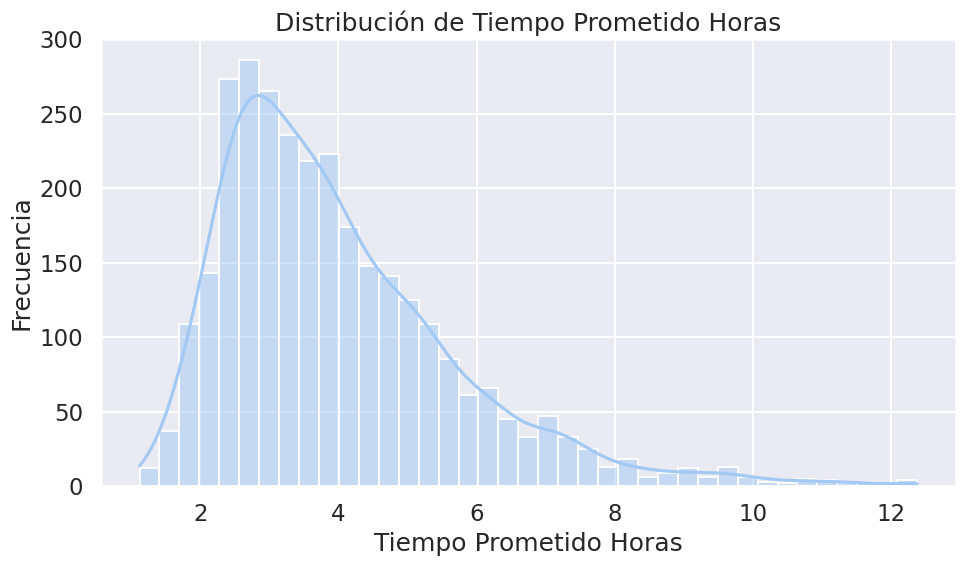

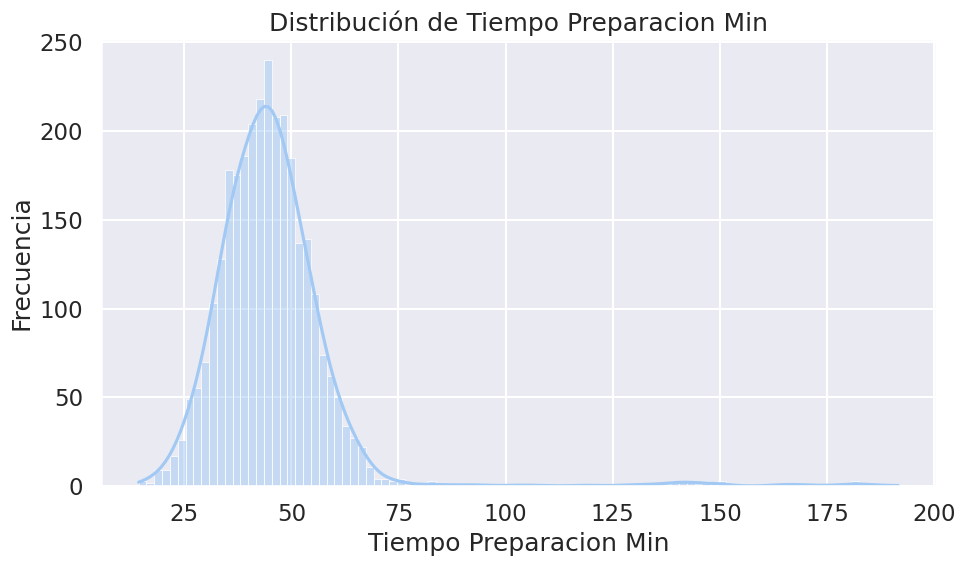

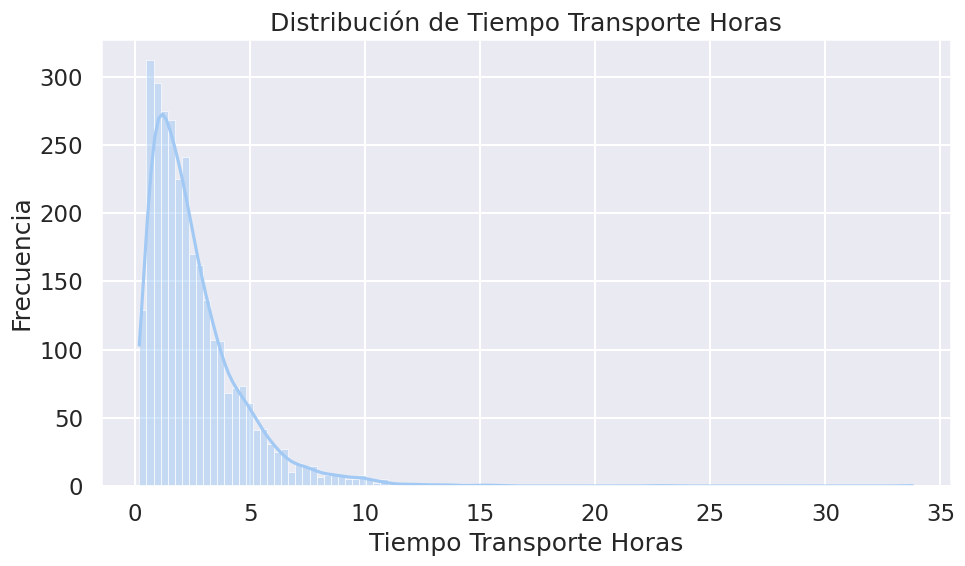

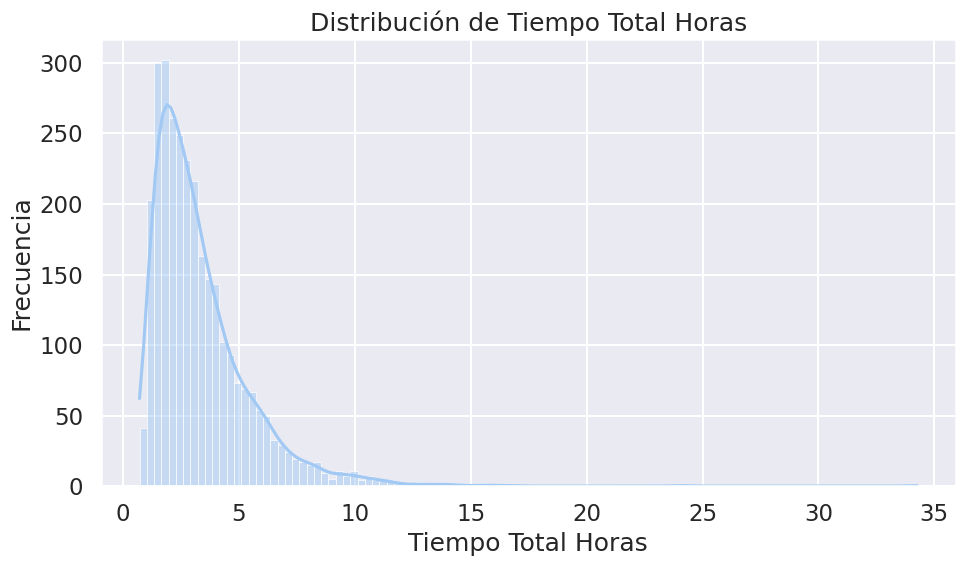

In [ ]:
# Graficos de Distribución de Tiempos

import matplotlib.pyplot as plt
import seaborn as sns

tiempo_columnas = ['tiempo_prometido_horas', 'tiempo_preparacion_min', 'tiempo_transporte_horas', 'tiempo_total_horas']

for columna in tiempo_columnas:
    plt.figure(figsize=(10, 6))
    sns.histplot(datos_RapidGo[columna], kde=True, palette='viridis')
    plt.title(f'Distribución de {columna.replace('_', ' ').title()}')
    plt.xlabel(columna.replace('_', ' ').title())
    plt.ylabel('Frecuencia')
    plt.tight_layout()
    plt.show()

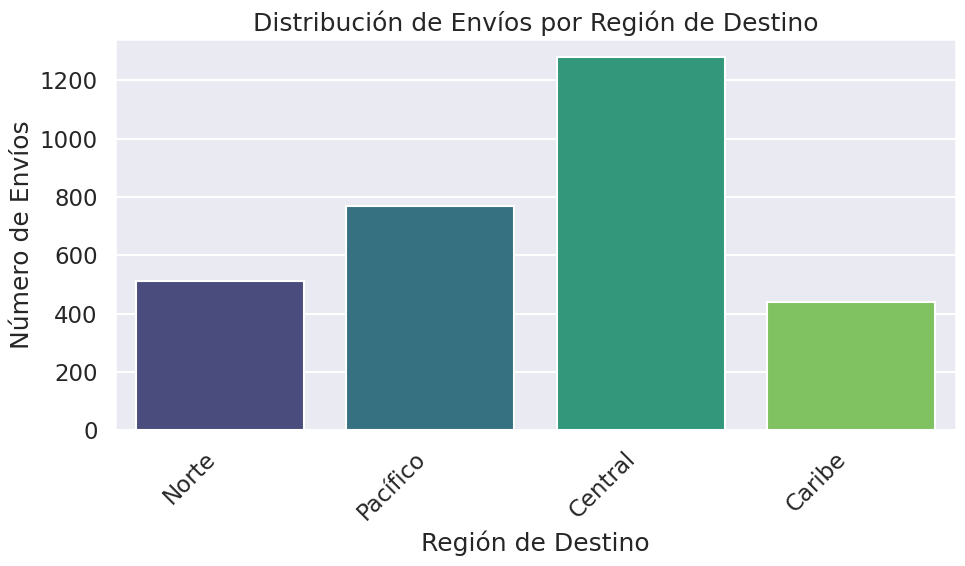

In [ ]:
# Gráfico Envíos por Región

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.countplot(data=datos_RapidGo, x='region_destino', palette='viridis')
plt.title('Distribución de Envíos por Región de Destino')
plt.xlabel('Región de Destino')
plt.ylabel('Número de Envíos')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

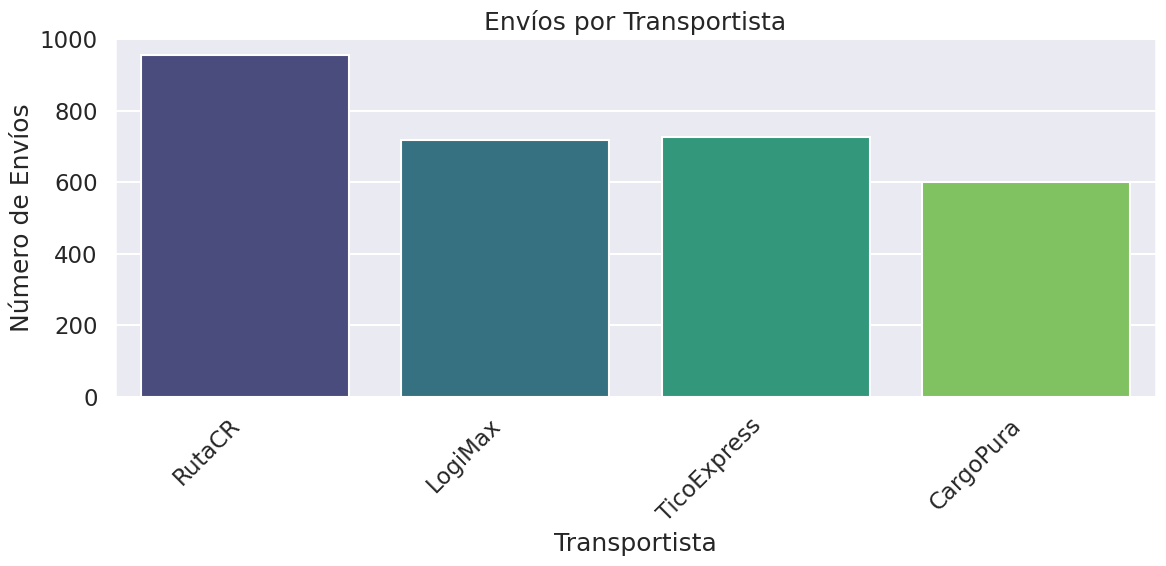

In [ ]:
# Gráfico Envíos por Transportista

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))
sns.countplot(data=datos_RapidGo, x='transportista', palette='viridis')
plt.title('Envíos por Transportista')
plt.xlabel('Transportista')
plt.ylabel('Número de Envíos')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

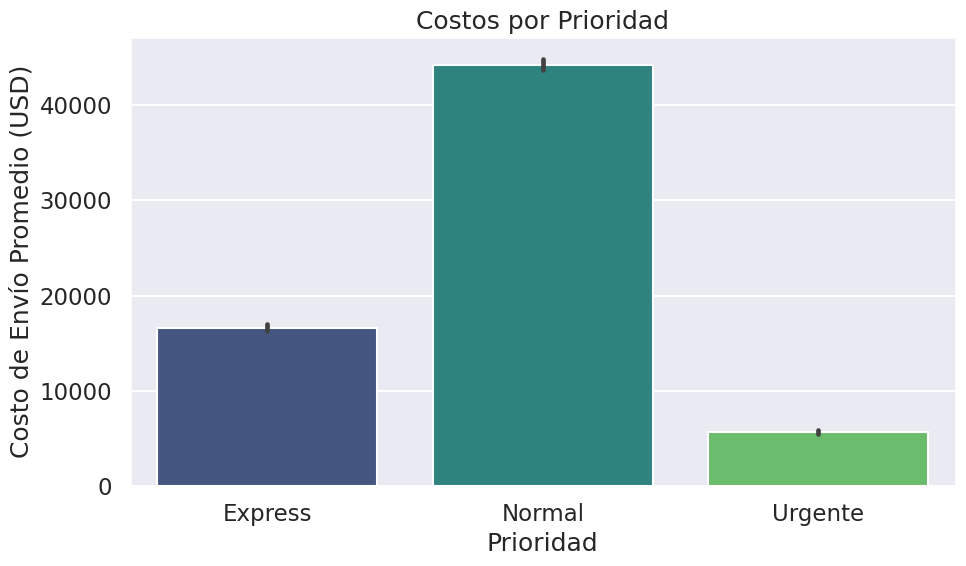

In [ ]:
# Gráfico Costos

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.barplot(data=datos_RapidGo, x='prioridad', y='costo_envio_usd', palette='viridis', estimator=sum)
plt.title('Costos por Prioridad')
plt.xlabel('Prioridad')
plt.ylabel('Costo de Envío Promedio (USD)')
plt.tight_layout()
plt.show()

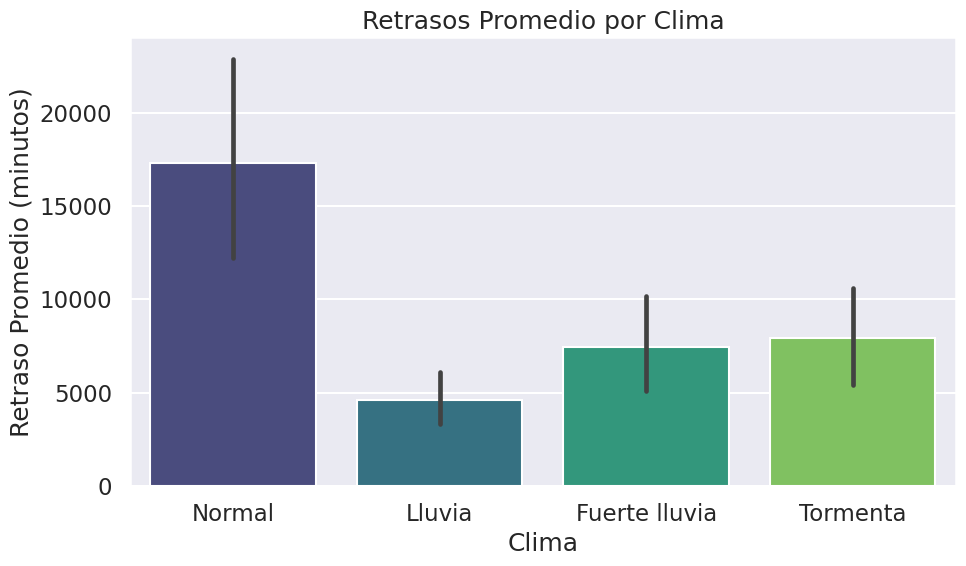

In [ ]:
# Gráfico Retrasos por Clima

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.barplot(data=datos_RapidGo, x='clima', y='retraso_minutos', palette='viridis', estimator=sum)
plt.title('Retrasos Promedio por Clima')
plt.xlabel('Clima')
plt.ylabel('Retraso Promedio (minutos)')
plt.tight_layout()
plt.show()

# 2. ¿Las principales variables se comportan como distribuciones normales?

Aquí evaluamos directamente lo que vieron de **normalidad.**

Las principales variables a estudiar podrían ser:

* tiempo_preparacion_min;
* tiempo_transporte_horas;
* tiempo_total_horas;
* costo_envio_usd.

# Lo que se espera que desarrollen

Para las variables seleccionadas:

* construir histogramas;
* construir Q-Q Plot;
* analizar asimetría;
* aplicar las pruebas de normalidad estudiadas;
* interpretar el p-value;
* determinar si existe o no evidencia para asumir normalidad.

No quiero solamente:

> *"p-value < 0.05, no es normal."*

Quiero que relacionen:

**resultado visual + prueba estadística + interpretación.**

# Pregunta que deben responder
>¿Es apropiado utilizar el promedio para describir todas las variables o existen casos donde la mediana representa mejor el comportamiento de RapidGo?

In [ ]:
#Tratamiento de Datos

import pandas as pd
import numpy as np

#Graficos
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import style

#Configurar los Estilos de los graficos
plt.style.use('ggplot')

#Preprocesado y analisis
from scipy import stats
import statsmodels.api as sm

#Configuramos los errores o advertencias
import warnings
warnings.filterwarnings('ignore')

In [ ]:
# Variables a Analizar

preparacion_min = datos_RapidGo['tiempo_preparacion_min']
transporte_horas = datos_RapidGo['tiempo_transporte_horas']
total_horas = datos_RapidGo['tiempo_total_horas']
costo_usd_envio = datos_RapidGo['costo_envio_usd']

In [ ]:
# Fórmula de Sturges

import math

def sturges_formula(n):
  k = 1 + 3.322 * math.log10(n)
  return round(k)

n = 3000   # reemplazar con la cantidad de filas del set de datos

num_bins = sturges_formula(n)
print('Numero de bines segun la formula de Sturges es: ', num_bins)

Numero de bines segun la formula de Sturges es:  13


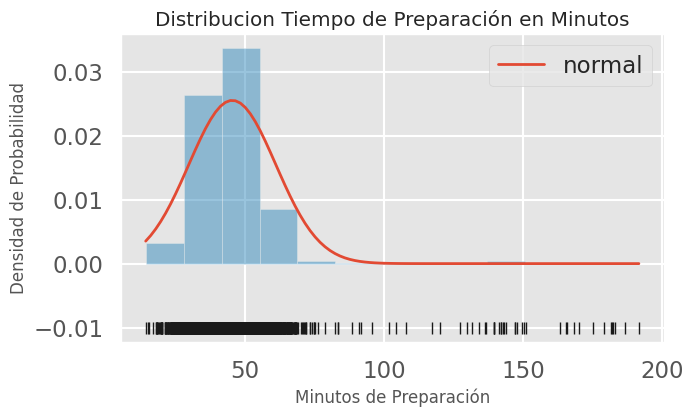

In [ ]:
## Histograma Tiempo de Preparación en minutos

#Valores de la media (mu) y desviacion estandar (sigma) de los datos

mu, sigma = stats.norm.fit(preparacion_min)

#Valores Teorico de la normaliadd del rango observado
x_hat = np.linspace(min(preparacion_min), max(preparacion_min), num = 100)
y_hat = stats.norm.pdf(x_hat, mu , sigma)

#Grafico
fig, ax = plt.subplots(figsize = (7,4))
ax.plot(x_hat, y_hat , linewidth = 2, label = 'normal')
ax.hist(x = preparacion_min, density= True, bins=num_bins, alpha = 0.5)
ax.plot(preparacion_min,np.full_like(preparacion_min,-0.01),'|k',markeredgewidth = 1)
ax.set_title('Distribucion Tiempo de Preparación en Minutos')
ax.set_xlabel('Minutos de Preparación')
ax.set_ylabel('Densidad de Probabilidad')
#ax.annotate('mu', [60,0.08])
ax.legend()
plt.show()


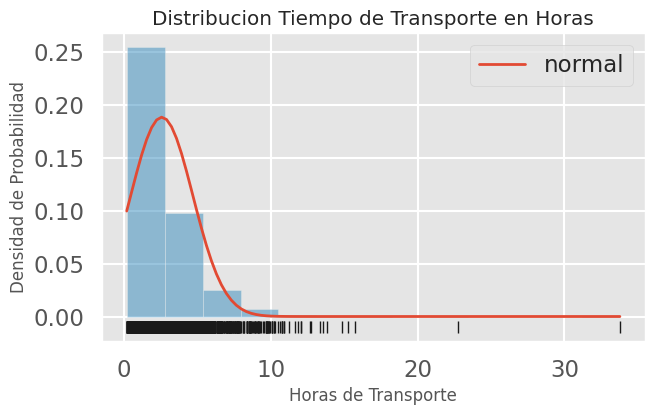

In [ ]:
## Histograma Tiempo de Transporte en Horas

#Valores de la media (mu) y desviacion estandar (sigma) de los datos
mu, sigma = stats.norm.fit(transporte_horas)

#Valores Teorico de la normaliadd del rango observado
x_hat = np.linspace(min(transporte_horas), max(transporte_horas), num = 100)
y_hat = stats.norm.pdf(x_hat, mu , sigma)

#Grafico
fig, ax = plt.subplots(figsize = (7,4))

ax.plot(x_hat, y_hat , linewidth = 2, label = 'normal')
ax.hist(x = transporte_horas, density= True, bins=num_bins, alpha = 0.5)
ax.plot(transporte_horas, np.full_like(transporte_horas,-0.01), '|k',markeredgewidth = 1)
ax.set_title('Distribucion Tiempo de Transporte en Horas')
ax.set_xlabel('Horas de Transporte')
ax.set_ylabel('Densidad de Probabilidad')
ax.legend()

plt.show()


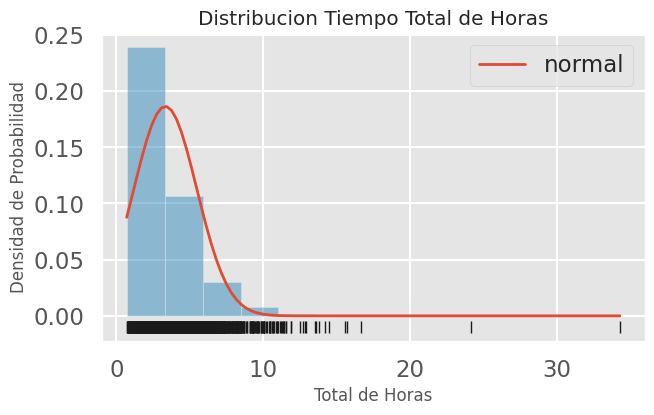

In [ ]:
## Histograma Tiempo Total de Horas

#Valores de la media (mu) y desviacion estandar (sigma) de los datos
mu, sigma = stats.norm.fit(total_horas)

#Valores Teorico de la normaliadd del rango observado
x_hat = np.linspace(min(total_horas), max(total_horas), num = 100)
y_hat = stats.norm.pdf(x_hat, mu , sigma)

#Grafico
fig, ax = plt.subplots(figsize = (7,4))

ax.plot(x_hat, y_hat , linewidth = 2, label = 'normal')
ax.hist(x = total_horas, density= True, bins=num_bins, alpha = 0.5)
ax.plot(total_horas, np.full_like(total_horas,-0.01), '|k',markeredgewidth = 1)
ax.set_title('Distribucion Tiempo Total de Horas')
ax.set_xlabel('Total de Horas')
ax.set_ylabel('Densidad de Probabilidad')
ax.legend()

plt.show()


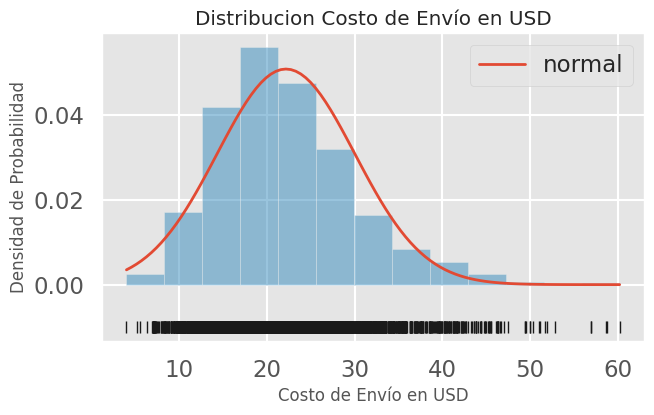

In [ ]:
## Histograma Costo de Envío en USD

#Valores de la media (mu) y desviacion estandar (sigma) de los datos
mu, sigma = stats.norm.fit(costo_usd_envio)

#Valores Teorico de la normaliadd del rango observado
x_hat = np.linspace(min(costo_usd_envio), max(costo_usd_envio), num = 100)
y_hat = stats.norm.pdf(x_hat, mu , sigma)

#Grafico
fig, ax = plt.subplots(figsize = (7,4))

ax.plot(x_hat, y_hat , linewidth = 2, label = 'normal')
ax.hist(x = costo_usd_envio, density= True, bins=num_bins, alpha = 0.5)
ax.plot(costo_usd_envio, np.full_like(costo_usd_envio,-0.01), '|k',markeredgewidth = 1)
ax.set_title('Distribucion Costo de Envío en USD')
ax.set_xlabel('Costo de Envío en USD')
ax.set_ylabel('Densidad de Probabilidad')
ax.legend()

plt.show()


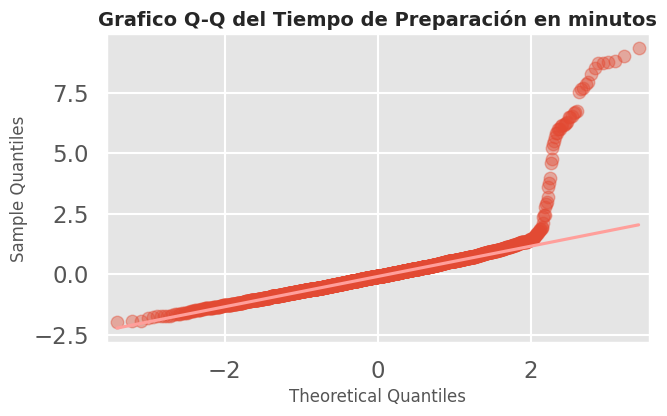

In [ ]:
# Grafico Q-Q Tiempo de Preparación en minutos

fig, ax = plt.subplots(figsize = (7,4))

sm.qqplot(
    preparacion_min,
    fit = True,
    line = 'q',
    alpha = 0.4,
    lw = 2,
    ax = ax)

ax.set_title('Grafico Q-Q del Tiempo de Preparación en minutos', fontsize = 14, fontweight = 'bold')
plt.show()

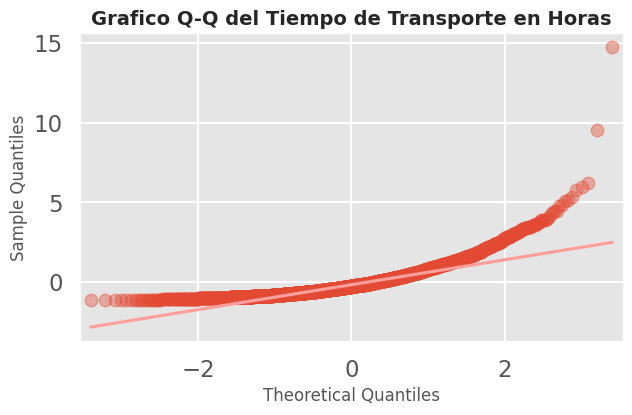

In [ ]:
# Grafico Q-Q Tiempo de Transporte en Horas

fig, ax = plt.subplots(figsize = (7,4))

sm.qqplot(
    transporte_horas,
    fit = True,
    line = 'q',
    alpha = 0.4,
    lw = 2,
    ax = ax)

ax.set_title('Grafico Q-Q del Tiempo de Transporte en Horas', fontsize = 14, fontweight = 'bold')
plt.show()

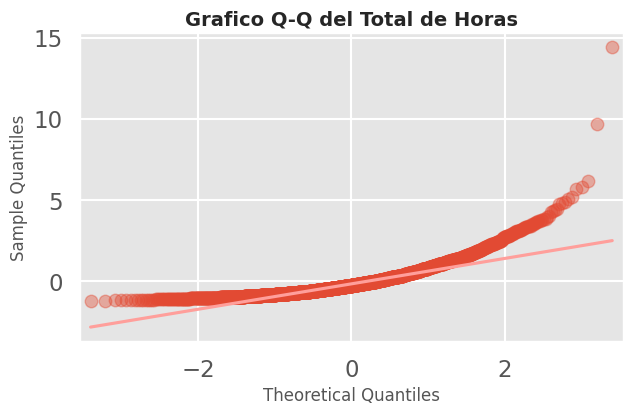

In [ ]:
# Grafico Q-Q Total de Horas

fig, ax = plt.subplots(figsize = (7,4))

sm.qqplot(
    total_horas,
    fit = True,
    line = 'q',
    alpha = 0.4,
    lw = 2,
    ax = ax)

ax.set_title('Grafico Q-Q del Total de Horas', fontsize = 14, fontweight = 'bold')
plt.show()

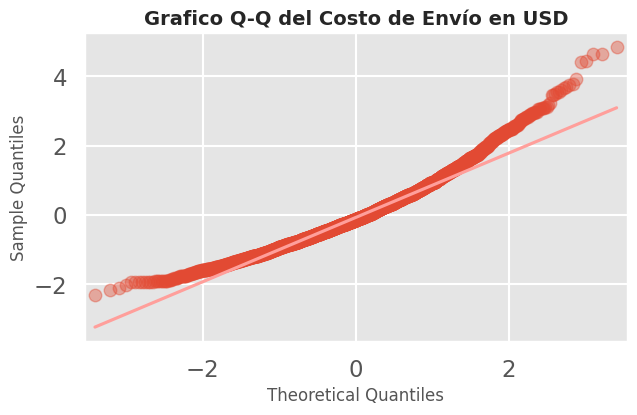

In [ ]:
# Grafico Q-Q Costo de Envío en USD

fig, ax = plt.subplots(figsize = (7,4))

sm.qqplot(
    costo_usd_envio,
    fit = True,
    line = 'q',
    alpha = 0.4,
    lw = 2,
    ax = ax)

ax.set_title('Grafico Q-Q del Costo de Envío en USD', fontsize = 14, fontweight = 'bold')
plt.show()

In [ ]:
# Análisis de Asimetría

print('Asimetria Preparacion en Minutos:',stats.skew(preparacion_min))
print('Curtosis Preparacion en Minutos:', stats.kurtosis(preparacion_min))

print('Asimetria Transporte en Horas:',stats.skew(transporte_horas))
print('Curtosis Transporte en Horas:', stats.kurtosis(transporte_horas))

print('Asimetria Total Horas:',stats.skew(total_horas))
print('Curtosis Total Horas:', stats.kurtosis(total_horas))

print('Asimetria Costo Envío en USD:',stats.skew(costo_usd_envio))
print('Curtosis Costo Envío en USD:', stats.kurtosis(costo_usd_envio))

Asimetria Preparacion en Minutos: 4.295923578644048
Curtosis Preparacion en Minutos: 30.049945657098185
Asimetria Transporte en Horas: 2.900798731026183
Curtosis Transporte en Horas: 21.744563480232983
Asimetria Total Horas: 2.8106680681338485
Curtosis Total Horas: 20.55028158097345
Asimetria Costo Envío en USD: 0.8434897768105565
Curtosis Costo Envío en USD: 1.1585451219379612


In [ ]:
# Shapiro-Wilk test Preparacion en Minutos

shapiro_test = stats.shapiro(preparacion_min)
shapiro_test


ShapiroResult(statistic=np.float64(0.679676277242282), pvalue=np.float64(7.194836995712012e-60))

In [ ]:
# Shapiro-Wilk test Transporte en Horas

shapiro_test = stats.shapiro(transporte_horas)
shapiro_test

ShapiroResult(statistic=np.float64(0.7957259180298307), pvalue=np.float64(6.347915335935704e-52))

In [ ]:
# Shapiro-Wilk test Total de Horas

shapiro_test = stats.shapiro(total_horas)
shapiro_test

ShapiroResult(statistic=np.float64(0.8042273787920053), pvalue=np.float64(3.3364149471920127e-51))

In [ ]:
# Shapiro-Wilk test Costo de Envío en USD

shapiro_test = stats.shapiro(costo_usd_envio)
shapiro_test

ShapiroResult(statistic=np.float64(0.9631043327264672), pvalue=np.float64(5.0995102417246505e-27))

In [ ]:
# D'Agostino's K-squared test Preparacion en Minutos

k2, p_value = stats.normaltest(preparacion_min)
print(f'Estadistico: {k2}, p-value: {p_value}')

Estadistico: 2747.14872435614, p-value: 0.0


In [ ]:
# D'Agostino's K-squared test Transporte en Horas

k2, p_value = stats.normaltest(transporte_horas)
print(f'Estadistico: {k2}, p-value: {p_value}')

Estadistico: 2090.045070194858, p-value: 0.0


In [ ]:
# D'Agostino's K-squared tesT Total de Horas

k2, p_value = stats.normaltest(total_horas)
print(f'Estadistico: {k2}, p-value: {p_value}')

Estadistico: 2032.575069666545, p-value: 0.0


In [ ]:
# D'Agostino's K-squared tesT Costo de Envío en USD

k2, p_value = stats.normaltest(costo_usd_envio)
print(f'Estadistico: {k2}, p-value: {p_value}')

Estadistico: 347.3415749755669, p-value: 3.764742928975014e-76


## Basado en los resultados y evidencias, se concluye que:

> ***NO existen argumentos estadísiticos para rechazar una Distribución Normal***

### De igual manera:
> ***Existen casos específicos donde la mediana se apega mayormente al comportamiento de los envíos de RapidGo¨***


# 3. ¿Existen envíos con comportamientos extremadamente diferentes al resto?

Aquí entra el bloque de **valores atípicos univariantes.**

##Lo que se espera que desarrollen

Seleccionar variables numéricas relevantes, por ejemplo:

* tiempo total;
* tiempo de transporte;
* retraso;
* costo;
* peso.

Aplicar una de las técnicas vistas en clase:
* IQR;
* desviación estándar;
* Z-score.

Pueden apoyarse con:
* boxplots;
* histogramas;
* gráficos de puntos.

## Después de detectar los outliers

No deben eliminarlos inmediatamente.

Deben revisar los registros y analizar variables como:

* clima;
* incidente;
* distancia;
* prioridad;
* peso;
* región.

Pregunta de negocio
> ***¿Los valores extremos encontrados parecen errores de los datos o situaciones extraordinarias pero reales de la operación?***

Y después:
> ***¿Qué tratamiento recomienda aplicar a esos valores y por qué?***

Pueden decidir:
* conservar;
* eliminar;
* analizar por separado;
* transformar;
* modificar si existe evidencia de error.

In [ ]:
# Variables Numéricas

tiempo_total = datos_RapidGo['tiempo_total_horas']
tiempo_transporte = datos_RapidGo['tiempo_transporte_horas']
retraso = datos_RapidGo['retraso_minutos']
costo = datos_RapidGo['costo_envio_usd']
peso = datos_RapidGo['peso_kg']


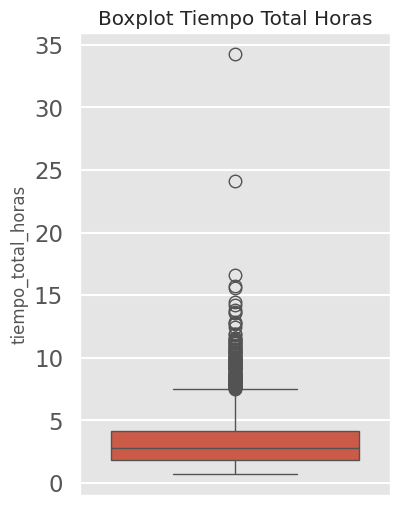

In [ ]:
# Boxplot Tiempo Total

plt.figure(figsize=(4, 6))
sns.boxplot(y = datos_RapidGo['tiempo_total_horas'])
plt.title('Boxplot Tiempo Total Horas')
plt.show()

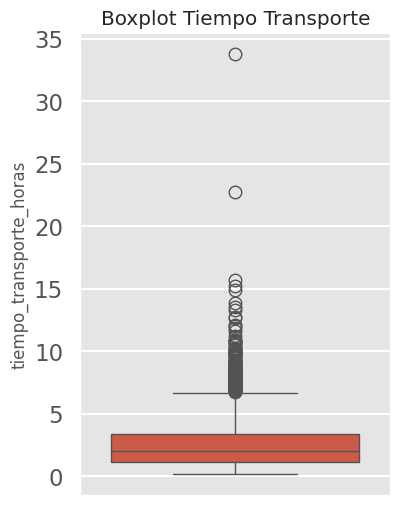

In [ ]:
# Boxplot Tiempo Transporte

plt.figure(figsize=(4, 6))
sns.boxplot(y = datos_RapidGo['tiempo_transporte_horas'])
plt.title('Boxplot Tiempo Transporte')
plt.show()

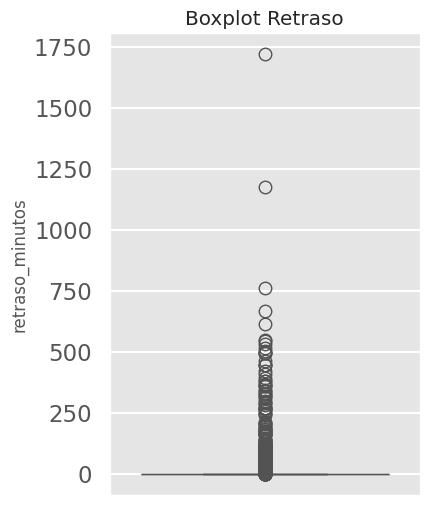

In [ ]:
# Boxplot Retraso

plt.figure(figsize=(4, 6))
sns.boxplot(y = datos_RapidGo['retraso_minutos'])
plt.title('Boxplot Retraso')
plt.show()

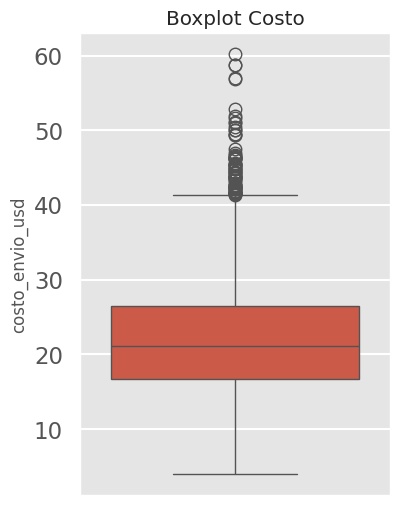

In [ ]:
# Boxplot Costo

plt.figure(figsize=(4, 6))
sns.boxplot(y = datos_RapidGo['costo_envio_usd'])
plt.title('Boxplot Costo')
plt.show()

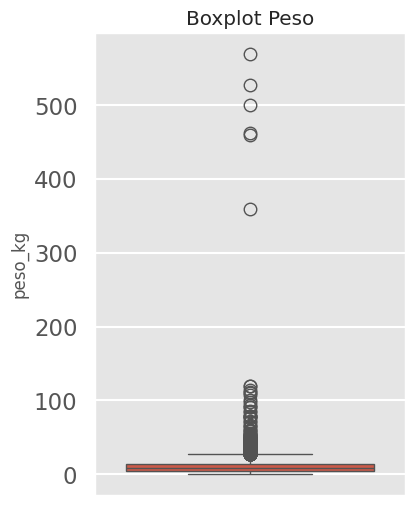

In [ ]:
# Boxplot Peso

plt.figure(figsize=(4, 6))
sns.boxplot(y = datos_RapidGo['peso_kg'])
plt.title('Boxplot Peso')
plt.show()

In [ ]:
# Funcion para detectar Outlier

def fuera_rango_iqr(dataset, columna, factor = 1.5):
  Q1 = np.quantile(dataset[columna], 0.25)
  Q3 = np.quantile(dataset[columna], 0.75)
  IQR = Q3 - Q1
  lim_inf = Q1 - factor * IQR
  lim_sup = Q3 + factor * IQR

  df1 = dataset[dataset[columna]  > lim_sup]
  df2 = dataset[dataset[columna]  < lim_inf]

  print(f"[{columna}] IQR:  {IQR:.2f}  | Inferior: {lim_inf:.2f} | Superior: {lim_sup:.2f}")
  print(f"[{columna}] Valores atípicos detectados: {df1.shape[0] + df2.shape[0]}")

  return lim_inf, lim_sup

In [ ]:
def graficar_outliers_iqr(dataset, columna, lim_inf, lim_sup):
  """
  Grafico de Histograma con zonas de valores atipicos segun el metodo del IQR
  """

  plt.figure(figsize=(10, 6))

  # Histograma con KDE para distribucion
  sns.histplot(dataset[columna], kde = True, bins = 30, color = 'skyblue')

  # Mediana
  mediana = dataset[columna].median()
  plt.axvline(x = mediana, color = 'blue', linestyle = 'dashed', linewidth = 1, label = 'Mediana')

  # Limite IQR
  plt.axvline(x = lim_inf, color = 'red', linestyle = 'dashed', linewidth = 1, label = "Limite Inferior")
  plt.axvline(x = lim_sup, color = 'red', linestyle = 'dashed', linewidth = 1, label =  "Limite Superior")

  # Áreas rojas de outliers
  if dataset[columna].min() < lim_inf:
    plt.axvspan(dataset[columna].min(), lim_inf, color = 'red', alpha = 0.2)
  if dataset[columna].max() > lim_sup:
    plt.axvspan(lim_sup, dataset[columna].max(), color = 'red', alpha = 0.2)

  # Titulo y Leyenda
  plt.title(f'Distribucion con valores atipicos (IQR) en {columna}')
  plt.legend(fontsize = 10, loc = 'upper left', frameon = True, fancybox = True, framealpha = 0.5)
  plt.xlabel(columna)
  plt.ylabel('Frecuencia')
  plt.show()

In [ ]:
# Función para eliminar los Valores Atípicos (Outliers)

def eliminar_outliers_iqr(dataset, columna):
  """
  Elimina los valores atipicos segun el metodo del IQR
  """

  lim_inf, lim_sup = fuera_rango_iqr(dataset, columna)
  df_filtrado = dataset[(dataset[columna] >= lim_inf) & (dataset[columna] <= lim_sup)]

  return df_filtrado

[tiempo_total_horas] IQR:  2.26  | Inferior: -1.52 | Superior: 7.53
[tiempo_total_horas] Valores atípicos detectados: 135


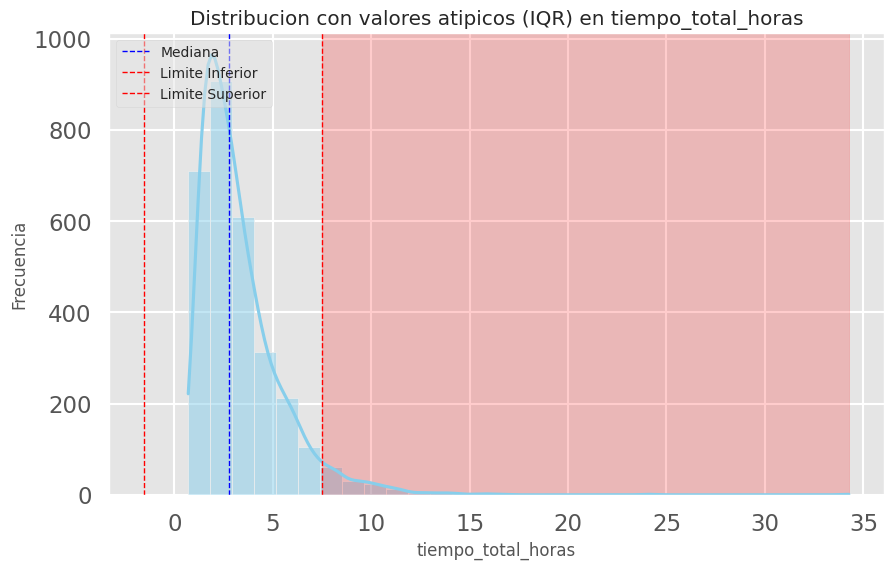

In [ ]:
# Valores Atípicos (Outliers) de Tiempo Total Horas

# Paso 1: Calcular los limites
inferior, superior = fuera_rango_iqr(datos_RapidGo, 'tiempo_total_horas')

# Paso 2: Graficar
graficar_outliers_iqr(datos_RapidGo, 'tiempo_total_horas', inferior, superior)


[tiempo_transporte_horas] IQR:  2.23  | Inferior: -2.21 | Superior: 6.71
[tiempo_transporte_horas] Valores atípicos detectados: 132


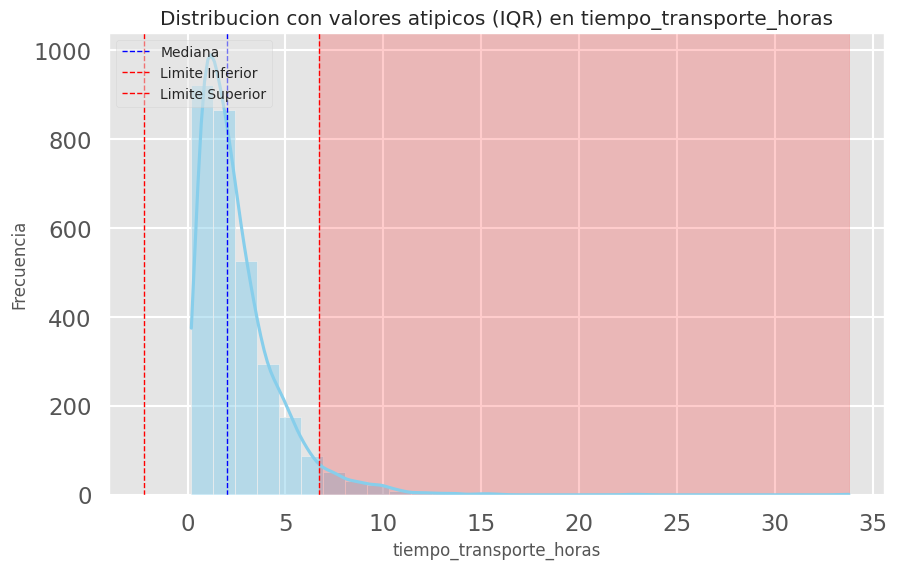

In [ ]:
# Valores Atípicos (Outliers) de Tiempo Transporte

# Paso 1: Calcular los limites
inferior, superior = fuera_rango_iqr(datos_RapidGo, 'tiempo_transporte_horas')

# Paso 2: Graficar
graficar_outliers_iqr(datos_RapidGo, 'tiempo_transporte_horas', inferior, superior)


[retraso_minutos] IQR:  0.00  | Inferior: 0.00 | Superior: 0.00
[retraso_minutos] Valores atípicos detectados: 402


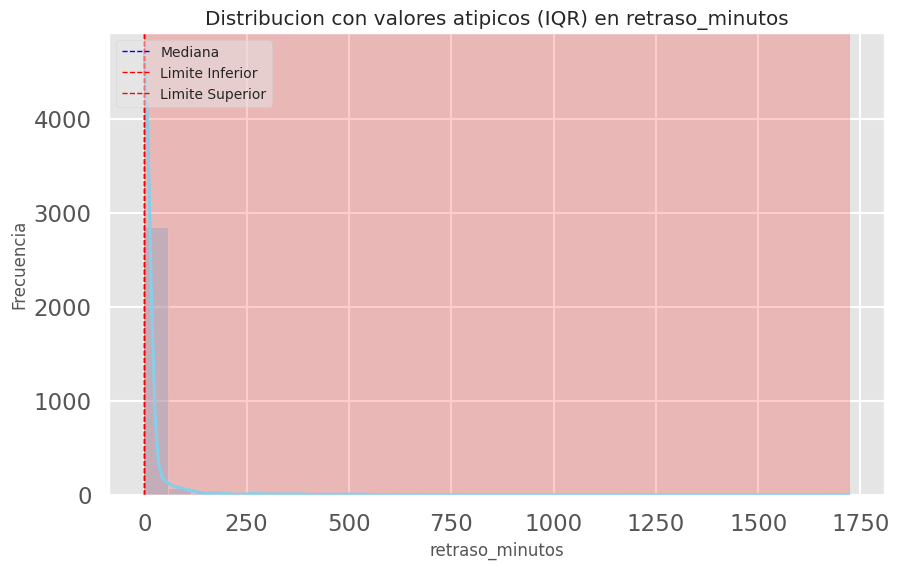

In [ ]:
# Valores Atípicos (Outliers) de Retraso

# Paso 1: Calcular los limites
inferior, superior = fuera_rango_iqr(datos_RapidGo, 'retraso_minutos')

# Paso 2: Graficar
graficar_outliers_iqr(datos_RapidGo, 'retraso_minutos', inferior, superior)


[costo_envio_usd] IQR:  9.85  | Inferior: 1.93 | Superior: 41.32
[costo_envio_usd] Valores atípicos detectados: 71


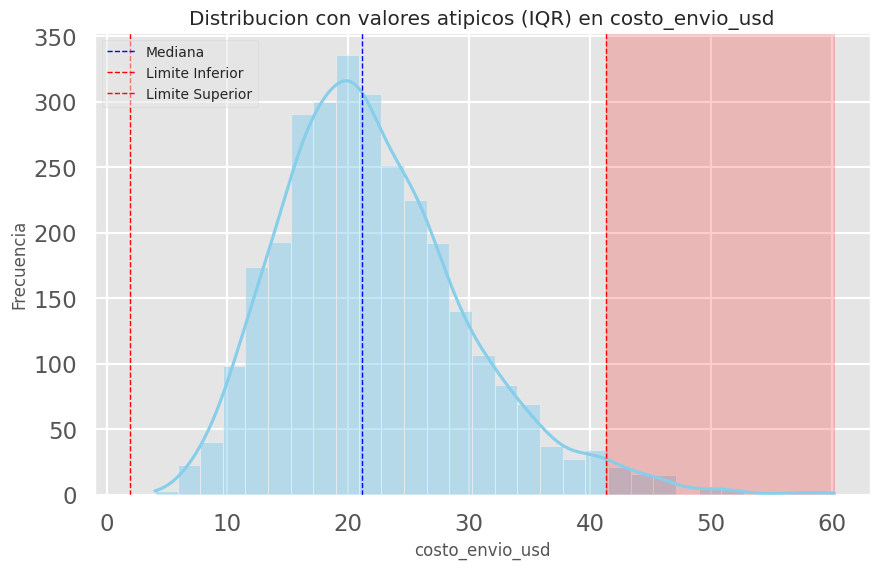

In [ ]:
# Valores Atípicos (Outliers) de Costo

# Paso 1: Calcular los limites
inferior, superior = fuera_rango_iqr(datos_RapidGo, 'costo_envio_usd')

# Paso 2: Graficar
graficar_outliers_iqr(datos_RapidGo, 'costo_envio_usd', inferior, superior)


[peso_kg] IQR:  9.01  | Inferior: -8.95 | Superior: 27.07
[peso_kg] Valores atípicos detectados: 191


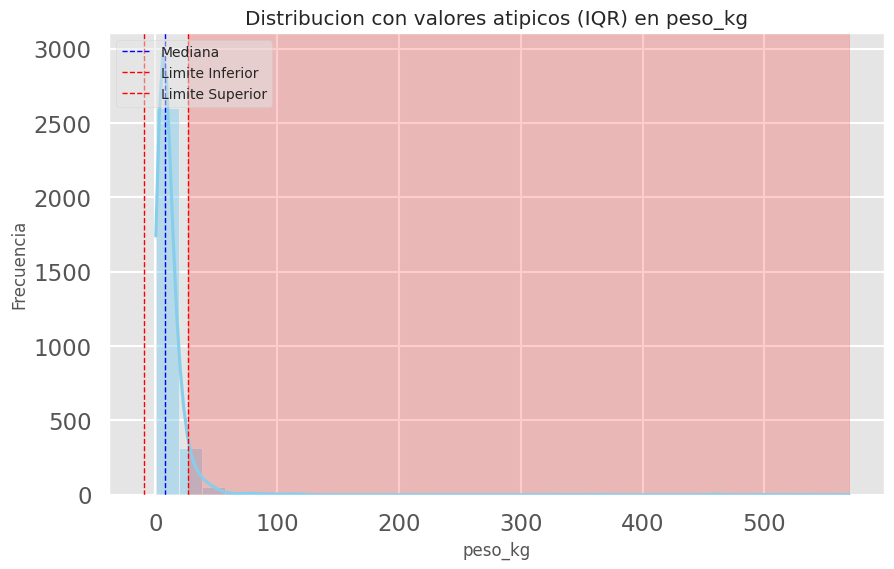

In [ ]:
# Valores Atípicos (Outliers) de Peso

# Paso 1: Calcular los limites
inferior, superior = fuera_rango_iqr(datos_RapidGo, 'peso_kg')

# Paso 2: Graficar
graficar_outliers_iqr(datos_RapidGo, 'peso_kg', inferior, superior)


## 4. ¿Cambian las conclusiones cuando se tratan los valores atípicos?

### Lo que se espera que desarrollen

Crear una copia del dataset y aplicar el tratamiento que hayan seleccionado en la pregunta anterior.

Posteriormente comparar:

### Antes

* media
* mediana
* desviación estándar
* distribución
* gráficos

### Después

* media
* mediana
* desviación estándar
* distribución
* gráficos

También pueden volver a ejecutar alguna prueba de normalidad.

### Pregunta de negocio

> ***¿Los valores atípicos estaban distorsionando de forma importante la percepción del desempeño de RapidGo?***

Por ejemplo, podrían concluir:

> *"El promedio de tiempo total disminuye considerablemente después de retirar registros claramente erróneos, mientras que la mediana prácticamente no cambia."*

In [ ]:
# Crear una copia del Dataset
dsRapidGo_Copia = datos_RapidGo.copy()

# Se eliminan los Datos Atípicos en la copia del Dataset
dsRapidGo_Copia = eliminar_outliers_iqr(dsRapidGo_Copia, 'tiempo_total_horas')
dsRapidGo_Copia = eliminar_outliers_iqr(dsRapidGo_Copia, 'tiempo_transporte_horas')
dsRapidGo_Copia = eliminar_outliers_iqr(dsRapidGo_Copia, 'retraso_minutos')
dsRapidGo_Copia = eliminar_outliers_iqr(dsRapidGo_Copia, 'costo_envio_usd')
dsRapidGo_Copia = eliminar_outliers_iqr(dsRapidGo_Copia, 'peso_kg')


[tiempo_total_horas] IQR:  2.26  | Inferior: -1.52 | Superior: 7.53
[tiempo_total_horas] Valores atípicos detectados: 135
[tiempo_transporte_horas] IQR:  2.04  | Inferior: -1.97 | Superior: 6.19
[tiempo_transporte_horas] Valores atípicos detectados: 39
[retraso_minutos] IQR:  0.00  | Inferior: 0.00 | Superior: 0.00
[retraso_minutos] Valores atípicos detectados: 298
[costo_envio_usd] IQR:  8.96  | Inferior: 2.73 | Superior: 38.56
[costo_envio_usd] Valores atípicos detectados: 45
[peso_kg] IQR:  8.66  | Inferior: -8.45 | Superior: 26.20
[peso_kg] Valores atípicos detectados: 147


In [ ]:
# Media Dataset Original vs Copia

print(f'Media Tiempo Total Horas: {round(datos_RapidGo["tiempo_total_horas"].mean(),2)}')
print(f'Media Tiempo transporte Horas: {round(datos_RapidGo["tiempo_transporte_horas"].mean(),2)}')
print(f'Media Retraso Minutos: {round(datos_RapidGo["retraso_minutos"].mean(),2)}')
print(f'Media Costo Envio USD: {round(datos_RapidGo["costo_envio_usd"].mean(),2)}')
print(f'Media Peso Kgs: {round(datos_RapidGo["peso_kg"].mean(),2)}')

print(f'Copia Media Tiempo Total Horas: {round(dsRapidGo_Copia["tiempo_total_horas"].mean(),2)}')
print(f'Copia Media Tiempo transporte Horas: {round(dsRapidGo_Copia["tiempo_transporte_horas"].mean(),2)}')
print(f'Copia Media Retraso Minutos: {round(dsRapidGo_Copia["retraso_minutos"].mean(),2)}')
print(f'Copia Media Costo Envio USD: {round(dsRapidGo_Copia["costo_envio_usd"].mean(),2)}')
print(f'Copia Media Peso Kgs: {round(dsRapidGo_Copia["peso_kg"].mean(),2)}')


Media Tiempo Total Horas: 3.34
Media Tiempo transporte Horas: 2.58
Media Retraso Minutos: 12.44
Media Costo Envio USD: 22.18
Media Peso Kgs: 12.03
Copia Media Tiempo Total Horas: 2.77
Copia Media Tiempo transporte Horas: 2.04
Copia Media Retraso Minutos: 0.0
Copia Media Costo Envio USD: 20.28
Copia Media Peso Kgs: 8.79


In [ ]:
# Mediana Dataset Original vs Copia

print(f'Mediana Tiempo Total Horas: {round(datos_RapidGo["tiempo_total_horas"].median(),2)}')
print(f'Mediana Tiempo transporte Horas: {round(datos_RapidGo["tiempo_transporte_horas"].median(),2)}')
print(f'Mediana Retraso Minutos: {round(datos_RapidGo["retraso_minutos"].median(),2)}')
print(f'Mediana Costo Envio USD: {round(datos_RapidGo["costo_envio_usd"].median(),2)}')
print(f'Mediana Peso Kgs: {round(datos_RapidGo["peso_kg"].median(),2)}')

print(f'Copia Mediana Tiempo Total Horas: {round(dsRapidGo_Copia["tiempo_total_horas"].median(),2)}')
print(f'Copia Mediana Tiempo transporte Horas: {round(dsRapidGo_Copia["tiempo_transporte_horas"].median(),2)}')
print(f'Copia Mediana Retraso Minutos: {round(dsRapidGo_Copia["retraso_minutos"].median(),2)}')
print(f'Copia Mediana Costo Envio USD: {round(dsRapidGo_Copia["costo_envio_usd"].median(),2)}')
print(f'Copia Mediana Peso Kgs: {round(dsRapidGo_Copia["peso_kg"].median(),2)}')

Mediana Tiempo Total Horas: 2.78
Mediana Tiempo transporte Horas: 2.03
Mediana Retraso Minutos: 0.0
Mediana Costo Envio USD: 21.11
Mediana Peso Kgs: 8.0
Copia Mediana Tiempo Total Horas: 2.47
Copia Mediana Tiempo transporte Horas: 1.76
Copia Mediana Retraso Minutos: 0.0
Copia Mediana Costo Envio USD: 19.99
Copia Mediana Peso Kgs: 7.39


In [ ]:
# Desviación Estándar Dataset Original vs Copia

print(f'Desviación Estándar Tiempo Total Horas: {round(datos_RapidGo["tiempo_total_horas"].std(),2)}')
print(f'Desviación Estándar Tiempo transporte Horas: {round(datos_RapidGo["tiempo_transporte_horas"].std(),2)}')
print(f'Desviación Estándar Retraso Minutos: {round(datos_RapidGo["retraso_minutos"].std(),2)}')
print(f'Desviación Estándar Costo Envio USD: {round(datos_RapidGo["costo_envio_usd"].std(),2)}')
print(f'Desviación Estándar Peso Kgs: {round(datos_RapidGo["peso_kg"].std(),2)}')

print(f'Copia Desviación Estándar Tiempo Total Horas: {round(dsRapidGo_Copia["tiempo_total_horas"].std(),2)}')
print(f'Copia Desviación Estándar Tiempo transporte Horas: {round(dsRapidGo_Copia["tiempo_transporte_horas"].std(),2)}')
print(f'Copia Desviación Estándar Retraso Minutos: {round(dsRapidGo_Copia["retraso_minutos"].std(),2)}')
print(f'Copia Desviación Estándar Costo Envio USD: {round(dsRapidGo_Copia["costo_envio_usd"].std(),2)}')
print(f'Copia Desviación Estándar Peso Kgs: {round(dsRapidGo_Copia["peso_kg"].std(),2)}')

Desviación Estándar Tiempo Total Horas: 2.14
Desviación Estándar Tiempo transporte Horas: 2.12
Desviación Estándar Retraso Minutos: 65.57
Desviación Estándar Costo Envio USD: 7.86
Desviación Estándar Peso Kgs: 23.9
Copia Desviación Estándar Tiempo Total Horas: 1.31
Copia Desviación Estándar Tiempo transporte Horas: 1.3
Copia Desviación Estándar Retraso Minutos: 0.0
Copia Desviación Estándar Costo Envio USD: 6.1
Copia Desviación Estándar Peso Kgs: 5.61


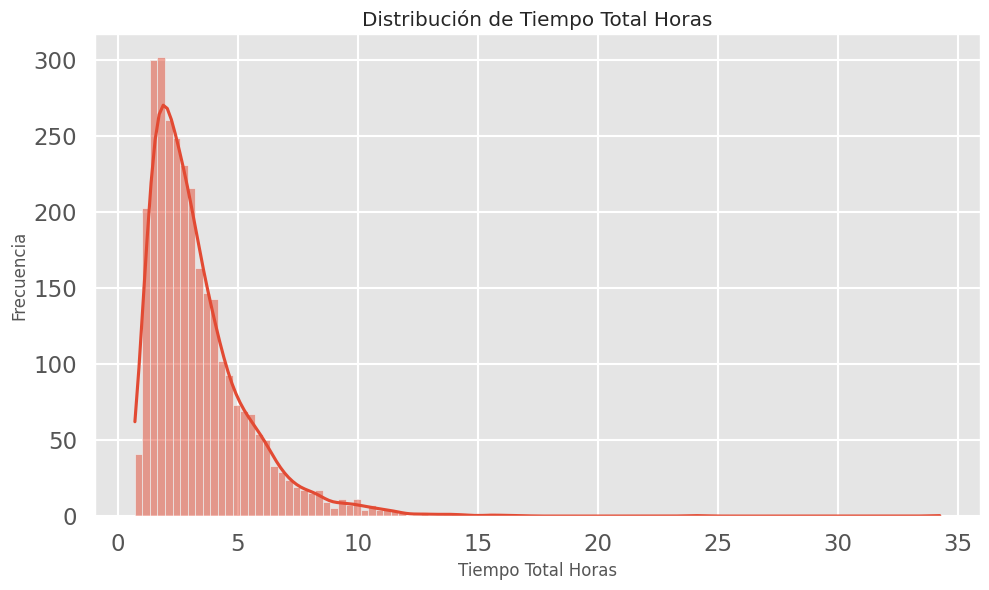

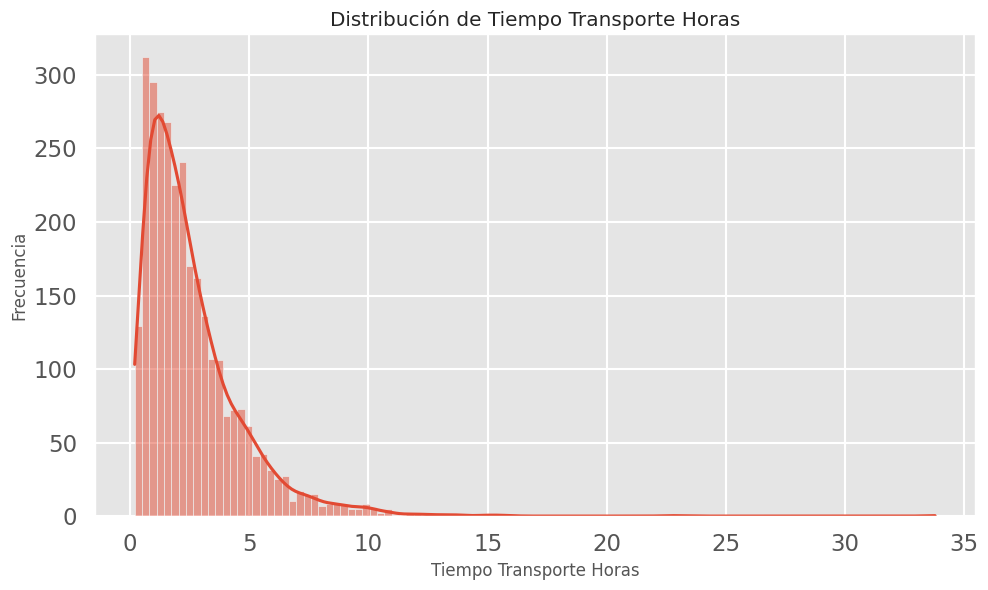

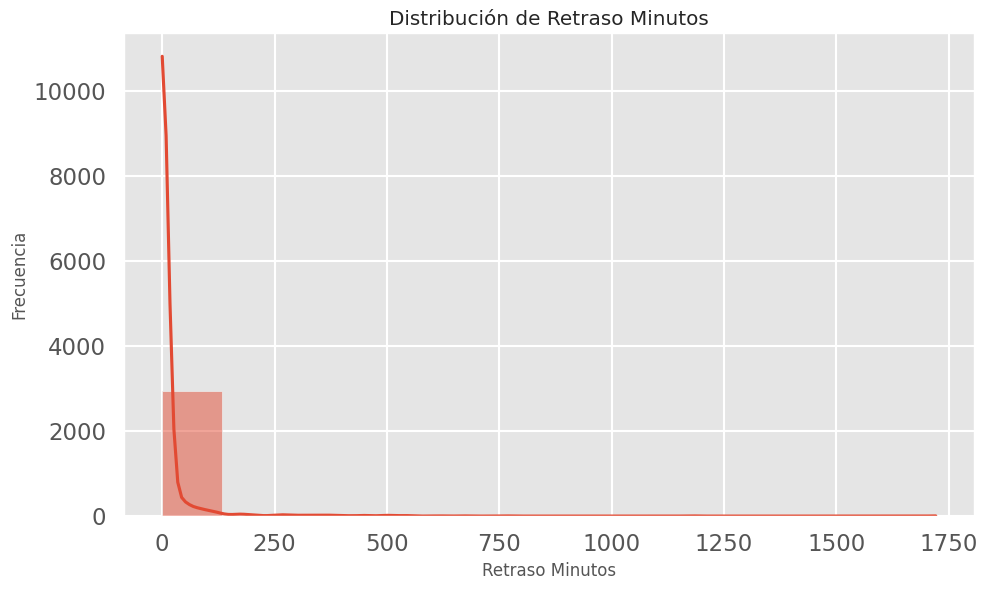

In [ ]:
# Graficos de Distribución de Tiempos

tiempo_columnas = ['tiempo_total_horas', 'tiempo_transporte_horas', 'retraso_minutos']

for columna in tiempo_columnas:
    plt.figure(figsize=(10, 6))
    sns.histplot(datos_RapidGo[columna], kde=True, palette='viridis')
    plt.title(f'Distribución de {columna.replace('_', ' ').title()}')
    plt.xlabel(columna.replace('_', ' ').title())
    plt.ylabel('Frecuencia')
    plt.tight_layout()
    plt.show()

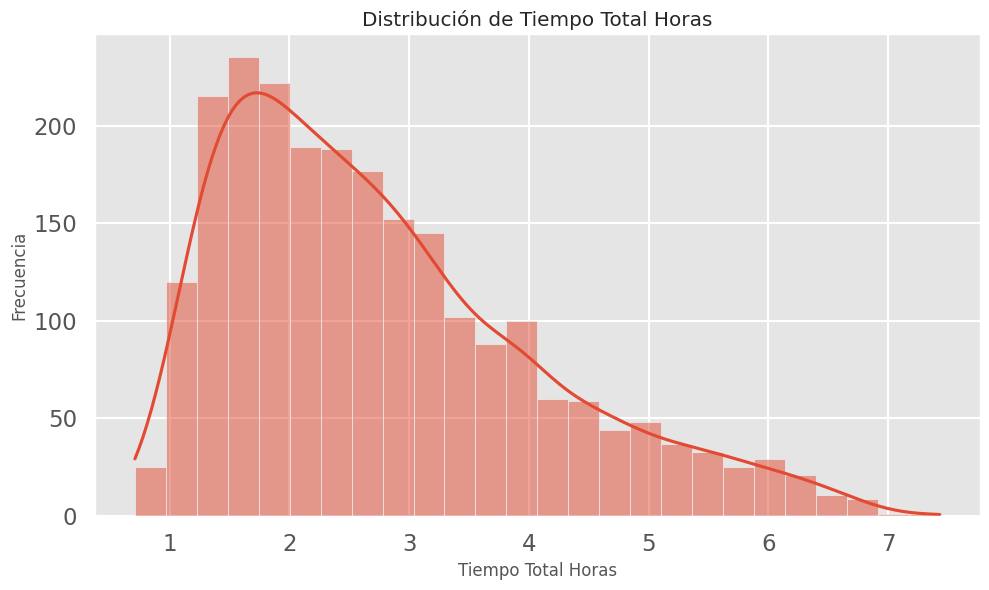

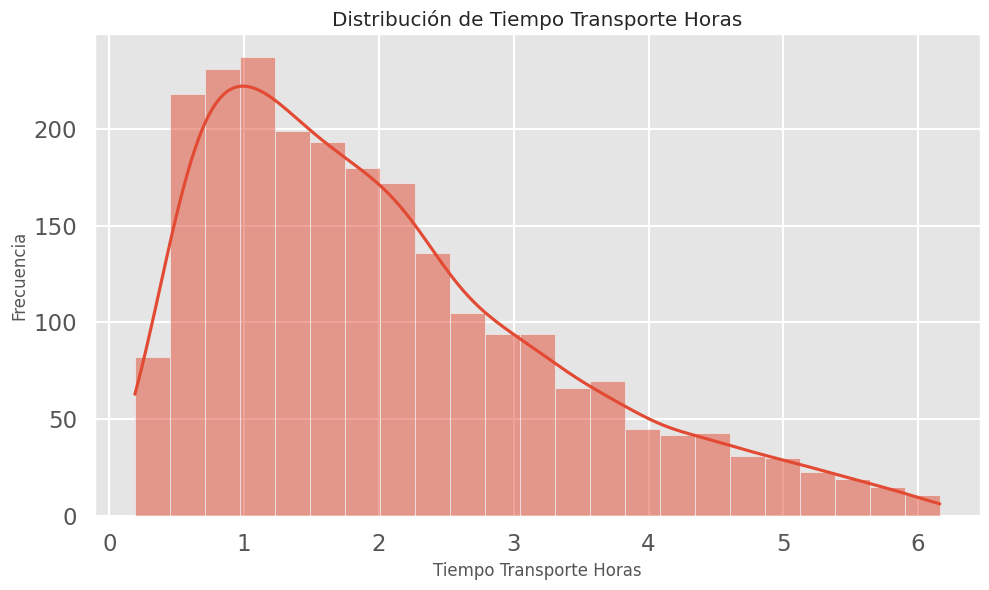

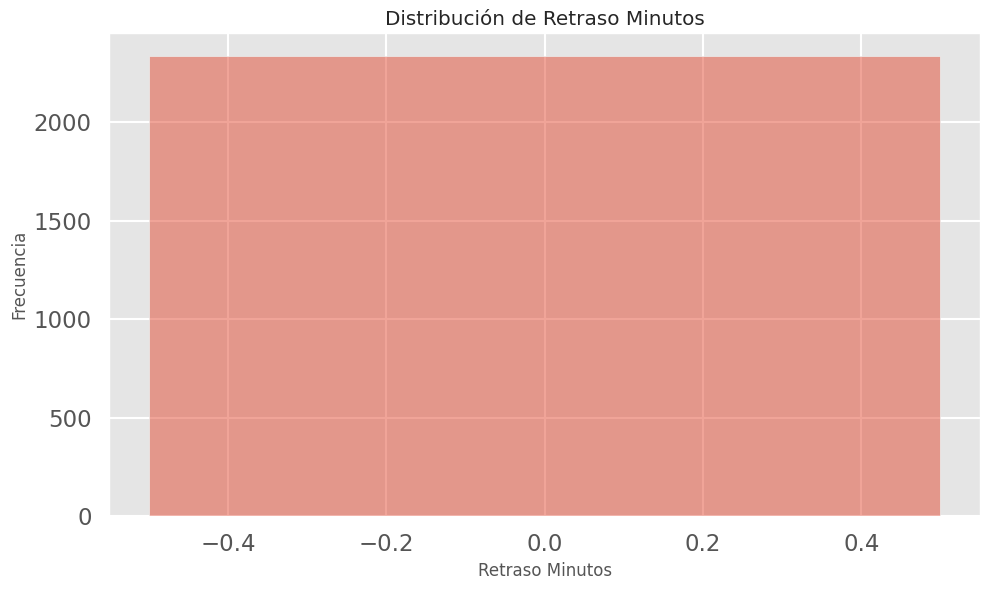

In [ ]:
# Graficos de Distribución de Tiempos Copia

tiempo_columnas = ['tiempo_total_horas', 'tiempo_transporte_horas', 'retraso_minutos']

for columna in tiempo_columnas:
    plt.figure(figsize=(10, 6))
    sns.histplot(dsRapidGo_Copia[columna], kde=True, palette='viridis')
    plt.title(f'Distribución de {columna.replace('_', ' ').title()}')
    plt.xlabel(columna.replace('_', ' ').title())
    plt.ylabel('Frecuencia')
    plt.tight_layout()
    plt.show()

Conclusión:

> *"El promedio de tiempo total disminuye después de eliminar los  registros erróneos, mientras que la mediana cambia pero de manera no muy significativa."*

## 5. ¿Existen envíos que son atípicos por la combinación de varias características?

Aquí entran **LOF y DBSCAN o Insolation Forest deben seleccionar unicamente una tecnica**

LOF trabaja comparando la **densidad local de un punto con la densidad de sus vecinos.**

DBSCAN, por su parte, utiliza:
* epsilon;
* min_samples;

y puede identificar puntos que no pertenecen a ningún cluster como **ruido/outliers.**

## Lo que se espera que desarrollen
Seleccionar varias variables relacionadas, por ejemplo:
* distancia;
* peso;
* costo;
* tiempo total.

Antes de aplicar los algoritmos:
* seleccionar las variables;
* escalar los datos.

Después aplicar:
* LOF;
* DBSCAN.
* Insolation Forest

## Deben interpretar  
No basta con decir:
> *"Estos registros tienen -1."*

Deben revisar algunos de los registros detectados y explicar:
> ***¿Qué combinación de características hace que esos envíos sean diferentes de los demás?***

Finalmente:
> ***¿LOF , DBSCAN o Insolation Forest encuentran exactamente los mismos casos que IQR o Z-score?***

In [ ]:
def detectar_outlier_LOF(dataset, columnas, n_neighbors=20, contamination = 'auto'):
  """
  Detectar outliers usando Local Outlier Factor en multiples columnas

  """

  datos = dataset.copy()

  X = dataset[columnas].values
  X_scaled = StandardScaler().fit_transform(X)

  lof = LocalOutlierFactor(n_neighbors=n_neighbors, contamination=contamination)
  etiquetas = lof.fit_predict(X_scaled) #1 = normal, # -1 = outlier
  scores = lof.negative_outlier_factor_

  datos['LOF_outlier'] = etiquetas
  datos['LOF_score'] = scores

  return datos

In [ ]:
def graficar_outliers_LOF(dataset, columnas, etiqueta_col = 'LOF_outlier'):
  """
  Visualizar outliers vrs normales con 2 columnas en un espacio de 2 Dimensiones.
  Si hay mas de 2 columnas, se aplica un PCA para reducir las dimensiones a 2.
  Los puntos normales se grafican azul y los outliers rojo
  """

  if len(columnas) <2:
    raise ValueError("El dataset debe tener al menos 2 columnas numericas para graficar")

  #Reduccion con PCA si hay mas 2 columnas

  if len(columnas) > 2:
    print('Aplicando PCA para reducir las dimensiones...')
    X = dataset[columnas].values
    X_reducido = PCA(n_components=2, random_state=123).fit_transform(X)
    x_label, y_label = "PCA Componente 1", "PCA Componente 2"
  else:
    X_reducido = dataset[columnas].values
    x_label, y_label = columnas[0], columnas[1]

  #Obtener etiquetas de Outliers
  etiquetas = dataset[etiqueta_col].values
  normales = etiquetas == 1
  outliers = etiquetas == -1

  #Crear la figura
  plt.figure(figsize=(10,6))

  #Graficar los puntos normales
  plt.scatter(X_reducido[normales, 0], X_reducido[normales, 1],
              color='blue', label='Puntos Normales',
              edgecolor = 'black', alpha=0.7, s = 60)

  #Graficar los puntos outliers
  plt.scatter(X_reducido[outliers, 0], X_reducido[outliers, 1],
              color='red', label='Puntos Outliers',
              edgecolor = 'black', alpha=0.7, s = 60)

  #Etiquetas y leyenda
  plt.xlabel(x_label)
  plt.ylabel(y_label)
  plt.legend(loc = 'upper right')
  plt.title('Visualizacion de Outliers con LOF')
  plt.grid(True)
  plt.tight_layout()
  plt.show()

In [ ]:
def eliminar_outlier_LOF(dataset, conservar_columnas_aux = False):
  """
  Eliminar los outlier detectados por LOF en el dataframe nuevo
  """

  datos_filtrados = dataset[dataset['LOF_outlier'] == 1].copy()

  if not conservar_columnas_aux:
    datos_filtrados = datos_filtrados.drop(columns=['LOF_outlier', 'LOF_score'])

  print(f'Se eliminaron {dataset.shape[0] - datos_filtrados.shape[0]} filas aplicando LOF')

  return datos_filtrados

Aplicando PCA para reducir las dimensiones...


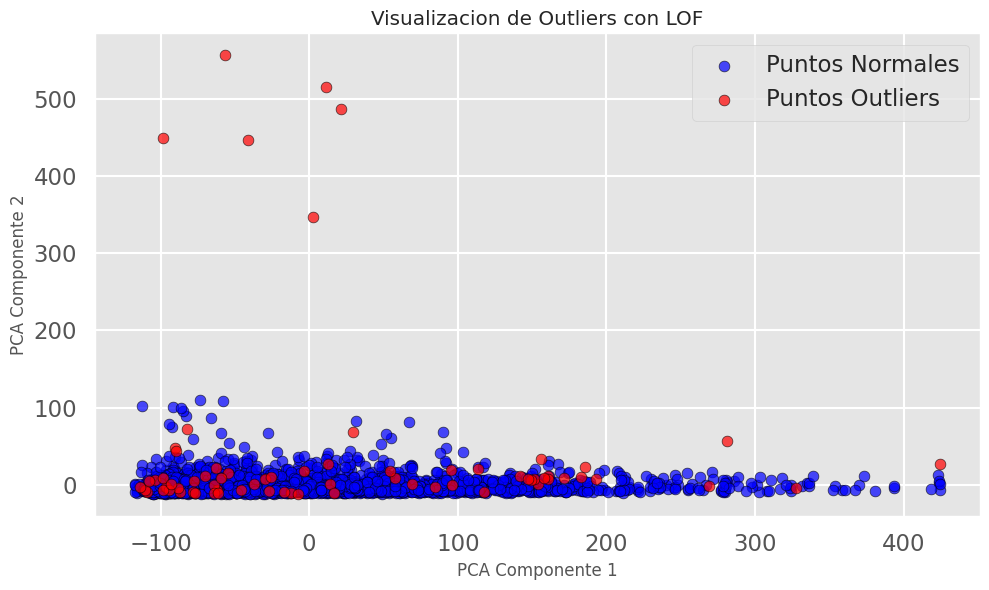

Se eliminaron 70 filas aplicando LOF


In [ ]:
# Paso 1: Definir las variables a analizar
columnas_numericas = ['distancia_km', 'peso_kg', 'tiempo_total_horas', 'costo_envio_usd']

# Paso 2: Detectar los outlier con LOF
datos_con_outliers = detectar_outlier_LOF(datos_RapidGo, columnas_numericas)

# Paso 3: Visualizar los outliers
graficar_outliers_LOF(datos_con_outliers, columnas_numericas)

#Paso 4: Filtrado de datos normales
datos_filtrados = eliminar_outlier_LOF(datos_con_outliers)

## 6. ¿El nuevo proceso realmente mejora la operación?

Esta es la parte de **A/B Testing.**

En el ejercicio que trabajaron en clase, el primer paso del experimento fue asignar clientes entre **Control y Tratamiento** y después verificar que ambos grupos fueran aproximadamente similares antes de interpretar el resultado.

Aquí harán lo mismo con RapidGo.

**Lo que se espera que desarrollen**

Primero comparar Control y Tratamiento antes de sacar conclusiones.

Revisar variables como:
* distancia;
* peso;
* prioridad;
* región;
* centro;
* tipo de producto.

La pregunta es:

> ***¿Los dos grupos parecen comparables?***

Después comparar resultados:
* tiempo de preparación;
* tiempo total;
* retraso;
* costo;
* entregas tardías.

Luego plantear:

## Hipótesis nula

El nuevo proceso **no produce una mejora.**

## Hipótesis alternativa

El nuevo proceso **produce una mejora.**

Aplicar la prueba estadística utilizada en clase.

Interpretar:

* estadístico;
* p-value;
* diferencia entre grupos.

En el caso trabajado anteriormente, un p-value inferior a 0.05 se interpretó como evidencia estadística de una diferencia entre los grupos.

## Pero deben ir más allá del p-value

También deben calcular:

*Diferencia= PromedioTratamiento − PromedioControl*

y, cuando tenga sentido:

Cambio%= Tratamiento − Control / Control×100

## Pregunta de negocio
> ***¿La mejora encontrada es solamente estadísticamente significativa o también parece importante desde el punto de vista operativo?***

In [ ]:
rng_ab = np.random.default_rng(2064)

experimento = datos_RapidGo[
    [
        "id_envio",
        "distancia_km",
        "peso_kg",
        "prioridad",
        "region_destino",
        "centro_distribucion",
        "tipo_producto"
    ]
].copy()

experimento = experimento.rename(
    columns={
        "distancia_km": "distancia",
        "peso_kg": "peso",
        "region_destino": "region",
        "centro_distribucion": "centro"
    }
)

experimento["grupo"] = rng_ab.choice(
    ["Control", "Tratamiento"],
    size=len(experimento),
    p=[0.50, 0.50]
)

experimento["tratamiento"] = (
    experimento["grupo"] == "Tratamiento"
).astype(int)

experimento.head()


,id_envio,distancia,peso,prioridad,region,centro,tipo_producto,grupo,tratamiento
0,RG-00001,138.82,48.19,Express,Norte,San José,General,Tratamiento,1
1,RG-00002,52.69,9.30,Normal,Pacífico,San José,Electrónica,Tratamiento,1
2,RG-00003,25.26,4.19,Normal,Central,Heredia,Frágil,Control,0
3,RG-00004,280.90,12.31,Normal,Caribe,Alajuela,Médico,Tratamiento,1
4,RG-00005,26.26,13.61,Normal,Central,Heredia,Frágil,Control,0


## 7. ¿Qué debería hacer RapidGo?
Deben utilizar todo lo encontrado anteriormente.

### Lo que se espera que desarrollen

Responder claramente:

> ***¿Recomienda implementar el nuevo proceso?***

La recomendación puede ser:
* implementarlo en toda la operación;
* implementarlo únicamente en determinados tipos de envío;
* realizar otra prueba antes de implementarlo;
* mantener el proceso actual.

### La conclusión debe incluir evidencia

Por ejemplo:

* comportamiento descriptivo;
* normalidad;
* impacto de los valores atípicos;
* resultado del A/B Testing;
* diferencia entre Control y Tratamiento;
* cambio en costos;
* cambio en retrasos.

## Formato esperado
Una conclusión ejecutiva breve, por ejemplo:

> ***"El nuevo proceso reduce el tiempo promedio de preparación en X minutos, equivalente a una mejora del X%. La diferencia entre Control y Tratamiento presenta evidencia estadística suficiente con un p-value de X. Sin embargo, el costo promedio por envío aumenta X%. Los resultados muestran que la mayor mejora se concentra en los envíos de prioridad normal. Por tanto, se recomienda implementar inicialmente el nuevo proceso en este segmento y monitorear costos y entregas tardías antes de extenderlo al resto de la operación."***

# Conclusión Final:

El nuevo proceso mejora el tiempo de preparación, reduciéndolo aproximadamente 7 minutos (p < 0.001).

El tiempo total también se reduce aproximadamente 5 minutos (p = 0.030).  

Sin embargo la magnitud de la mejora es relativamente pequeña.

Las entregas tardías tienen una reducción de 1.73 puntos porcentuales.
 No obstante, p = 0.164, por lo que no existe evidencia estadística suficiente para afirmar que el nuevo proceso reduzca las entregas tardías en toda la operación.  

Uno de los principales problemas es el costo que aumenta aproximadamente $0.90 (+4.16%), lo cual hace una diferencia estadísticamente significativa (p = 0.001).

Tambien se muestra que los grupos Control y Tratamiento resultaron suficientemente comparables antes de evaluar el efecto, por lo que la comparación del experimento es confiable.

## Recomendación

Todavía no es factible implementar el nuevo proceso en toda la operación.  

Basado en la evidencia mostrada, el proceso es prometedor, pero el beneficio principal está en la velocidad de preparación, y no existe suficiente evidencia de una mejora en entregas tardías, mientras que sí existe un incremento significativo del costo.

La mejor decisión sería realizar una implementación piloto segmentada, particularmente en:

* Prioridad Normal: reducción de preparación de aproximadamente 8.08 min.
* Prioridad Urgente: reducción de preparación de 5.20 min y una reducción significativa de entregas tardías.
* Evaluar con especial cuidado Express, donde el ahorro de preparación no se traduce claramente en menor tiempo total.

## ***RapidGo NO debería implementar todavía el nuevo proceso en toda la operación***